<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-01/lab-001-python-matplotlib-pandas.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 001 — Python, Matplotlib and Pandas

Deep learning is numerical work: data are generated or loaded, transformed, fitted, and plotted.
Before we touch neural networks we need three everyday tools:

| Tool | What it is for |
|---|---|
| **Python** | the programming language that connects all steps |
| **Matplotlib** | plotting |
| **Pandas** | tables of data (rows = measurements, columns = quantities) |

Section 1 is a ten-minute tour of Python itself: variables, lists, loops and functions.
Section 2 builds up Matplotlib figures gradually, from a single line to multi-panel figures, histograms and two-dimensional maps.
Section 3 uses Pandas to analyse a table of data from a simulated experiment that measures $g$ with a pendulum.
Section 4 explains classes and objects, that is, what `class`, `__init__`, `self` and `super()` mean; this is needed to read the PyTorch models of later notebooks.
Section 5 summarises the tools, and Section 6 contains exercises with solutions.

> Everything introduced here is used in the rest of the course; readers who know it can go straight to the exercises.

> The notebook runs in Google Colab without any installation:
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `matplotlib`, `pandas`) are pre-installed in Colab; no `pip install` required.
> 4. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

<hr/>
## 1. Python in 10 minutes

### 1.1 Cells, printing and variables
The value of the *last line* of a code cell is displayed automatically; anything else must be `print`-ed.

In code, `=` is not an equation but an **assignment**: `g = 9.81` stores the number 9.81 under the name `g`, and every later use of `g` means this number.
The right-hand side is evaluated first, so `n = n + 1` (meaningless as an equation) increases `n` by one. A comparison "is equal?" is written `==`.

In [1]:
# Everything after '#' is a comment: Python ignores it, humans read it.
g = 9.81          # gravitational acceleration [m/s^2]  -> a float (real number)
n_balls = 3       # an int (integer)
name = "Galileo"  # a str (string of characters)

print(name, "dropped", n_balls, "balls")
type(g)           # the last line of a cell is shown automatically

Galileo dropped 3 balls


float

**f-strings** are the most convenient way to format numbers in text. A string with the letter `f` before the opening quote, `f"..."`, may contain
expressions in braces `{...}`; each one is replaced by its value. The part after the colon controls the format:
`:.3f` → 3 decimals, `:.2e` → scientific notation.
A number in front of the dot is the minimum **width** in characters: `{h:6.2f}` always occupies at least 6 characters, padded with spaces on the left.
This keeps the columns of printed tables aligned. For strings the letter is `s`: `{name:8s}` pads a name to 8 characters.

In [2]:
t = 2.0                    # time [s]
h = 0.5 * g * t**2         # distance fallen; the power operator is **, not ^
print(f"After t = {t} s the ball has fallen h = {h:.3f} m  (= {h:.2e} m)")

After t = 2.0 s the ball has fallen h = 19.620 m  (= 1.96e+01 m)


### 1.2 Lists and loops
A **list** is an ordered collection. Indexing starts at **0**, not at 1. Negative indices count from the end.

In [3]:
times = [0.0, 0.5, 1.0, 1.5, 2.0]   # a list of floats

print("first element :", times[0])
print("last element  :", times[-1])
print("slice [1:3]   :", times[1:3], " <- elements 1 and 2; the end index is NOT included")
print("length        :", len(times))

first element : 0.0
last element  : 2.0
slice [1:3]   : [0.5, 1.0]  <- elements 1 and 2; the end index is NOT included
length        : 5


A `for` loop runs the indented block once for every element of the list: in `for t in times:` the name `t` takes the values `times[0]`, `times[1]`, ... in turn.
`heights.append(h)` is a **method call**: a function (`append`) that belongs to the list `heights` and is written after a dot. Methods are explained in Section 4.

In [4]:
# A 'for' loop repeats the indented block for each element.
# Indentation (4 spaces) is part of the Python syntax.
heights = []                       # start with an empty list
for t in times:
    h = 0.5 * g * t**2
    heights.append(h)              # add an element at the end of the list
    print(f"t = {t:.1f} s  ->  h = {h:6.2f} m")

t = 0.0 s  ->  h =   0.00 m
t = 0.5 s  ->  h =   1.23 m
t = 1.0 s  ->  h =   4.91 m
t = 1.5 s  ->  h =  11.04 m
t = 2.0 s  ->  h =  19.62 m


A **list comprehension** does the same in one line.
`[0.5 * g * t**2 for t in times]` reads like the set notation
$$\big\{\tfrac12 g t^2 \,:\, t \in \text{times}\big\}: \tag{1}$$
"the list of these values, one for every $t$ in `times`".

In [5]:
heights = [0.5 * g * t**2 for t in times]
heights

[0.0, 1.22625, 4.905, 11.03625, 19.62]

### 1.3 Conditions
`if condition:` runs the indented block only when the condition is true. `elif` ("else if") is tested only when all previous conditions were false,
and the `else` block runs when none of them was true. Conditions are built with the comparisons `<`, `<=`, `>`, `>=`, `==` (equal) and `!=` (not equal).

In [6]:
for h in heights:
    if h < 1.0:
        print(f"{h:6.2f} m : safe")
    elif h < 10.0:
        print(f"{h:6.2f} m : careful")
    else:
        print(f"{h:6.2f} m : dangerous")

  0.00 m : safe
  1.23 m : careful
  4.91 m : careful
 11.04 m : dangerous
 19.62 m : dangerous


### 1.4 Functions
A function is defined with `def name(arguments):` followed by an indented block;
`return` ends the function and gives back the result. Arguments can have **default values**, which are used when the argument is not given.
An argument can also be passed by name, as in `fall_height(2.0, g=1.62)`.
The text in triple quotes (*docstring*) documents what the function does.

In [7]:
def fall_height(t, g=9.81):
    """Distance [m] fallen from rest after time t [s] under constant acceleration g [m/s^2]."""
    return 0.5 * g * t**2

print(fall_height(2.0))           # uses the default g = 9.81 (Earth)
print(fall_height(2.0, g=1.62))   # Moon

19.62
3.24


### 1.5 Dictionaries
A **dictionary** maps *keys* to *values*. It is enclosed in curly braces as `{key: value, key: value, ...}` and is used for storing parameters or results.
`gravity["Moon"]` returns the value stored under the key `"Moon"`; `.items()` returns all (key, value) pairs, which a `for` loop can unpack into two variables.

In [8]:
gravity = {"Earth": 9.81, "Moon": 1.62, "Mars": 3.71, "Jupiter": 24.79}

for planet, g_planet in gravity.items():
    print(f"{planet:8s}: after 2 s the ball falls {fall_height(2.0, g_planet):6.2f} m")

Earth   : after 2 s the ball falls  19.62 m
Moon    : after 2 s the ball falls   3.24 m
Mars    : after 2 s the ball falls   7.42 m
Jupiter : after 2 s the ball falls  49.58 m


### 1.6 Getting help
`help(fall_height)`, or `fall_height?` in a notebook, shows the docstring of a function.
In Colab, hovering over a function name or pressing **Tab** after a dot (e.g. `np.` + Tab) lists the available options.
When an error occurs, the **last line** of the message says what went wrong, and the lines above it show where.

In [9]:
help(fall_height)

Help on function fall_height in module __main__:

fall_height(t, g=9.81)
    Distance [m] fallen from rest after time t [s] under constant acceleration g [m/s^2].



<hr/>
## 2. Matplotlib

Python lists are slow and inconvenient for maths, so for numbers we use **NumPy** arrays. NumPy and Matplotlib are **libraries** (packages of ready-made functions) that are not part of the core language;
`import numpy as np` loads NumPy and makes it available under the short name `np`, so that its functions are called as `np.sin`, `np.pi`, and so on.
The function `np.linspace(a, b, n)` returns `n` equally spaced points from `a` to `b`,
and mathematical functions such as `np.sin` and `np.exp` act on **all elements of an array at once**, so a whole curve is computed in one line.

In [10]:
import numpy as np                 # 'np' is the universal nickname
import matplotlib.pyplot as plt    # 'plt' likewise

x = np.linspace(0, 2 * np.pi, 9)   # 9 points between 0 and 2*pi
print(x)
print(np.sin(x).round(3))          # sin of every element; rounded for readability
# (-0. is a 'negative zero': a tiny negative number such as sin(2*pi) = -2.4e-16 rounded to 0)

[0.         0.78539816 1.57079633 2.35619449 3.14159265 3.92699082
 4.71238898 5.49778714 6.28318531]
[ 0.     0.707  1.     0.707  0.    -0.707 -1.    -0.707 -0.   ]


### 2.1 The simplest possible plot
`plt.plot(x, y)` draws straight segments between the points $(x_i, y_i)$, so with only 9 points the "sine" looks jagged.
`plt.show()` displays the figure built so far; the next plotting command then starts a new figure.

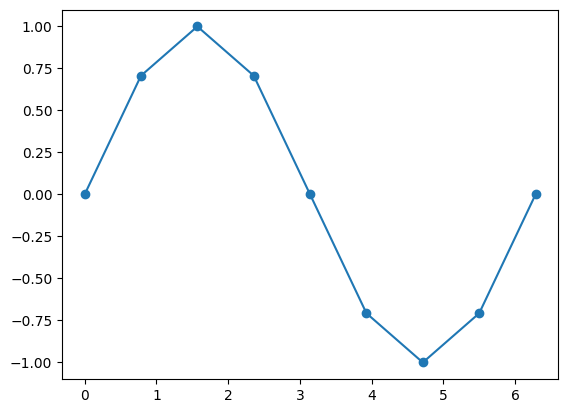

In [11]:
plt.plot(x, np.sin(x), "o-")       # "o-" = circles connected by lines
plt.show()

With 200 points the segments are too short to be seen.

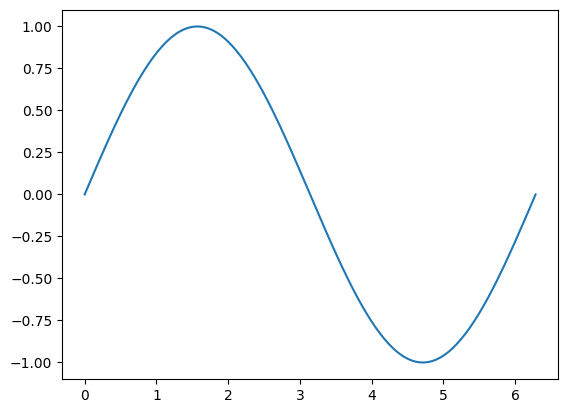

In [12]:
x = np.linspace(0, 2 * np.pi, 200)   # 200 points -> looks smooth
plt.plot(x, np.sin(x))
plt.show()

### 2.2 Labels, units and legends
A figure without axis labels is not a scientific figure. Always label axes, with units, and add a legend when there is more than one curve.
Matplotlib understands LaTeX between `$...$` — use **raw strings** `r"..."` so that backslashes work.

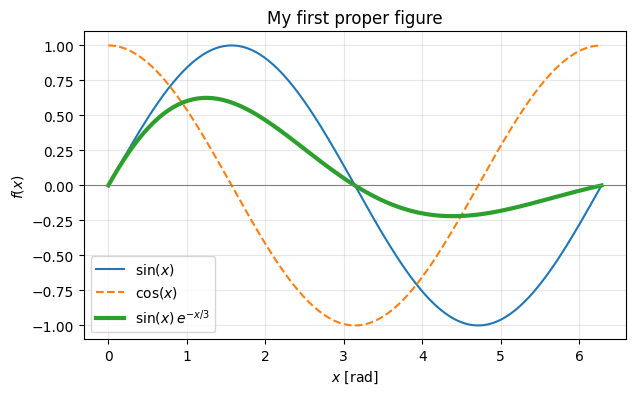

In [13]:
plt.figure(figsize=(7, 4))                       # width, height in inches
plt.plot(x, np.sin(x), label=r"$\sin(x)$")
plt.plot(x, np.cos(x), label=r"$\cos(x)$", linestyle="--")
plt.plot(x, np.sin(x) * np.exp(-x / 3), label=r"$\sin(x)\,e^{-x/3}$", linewidth=3)
plt.xlabel(r"$x$ [rad]")
plt.ylabel(r"$f(x)$")
plt.title("My first proper figure")
plt.axhline(0, color="gray", linewidth=0.8)       # horizontal reference line at y=0
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### 2.3 The object-oriented interface
For anything beyond a quick look we use the **object-oriented** style, `fig, ax = plt.subplots()`: `fig` is the whole canvas,
`ax` is one panel (one coordinate system). `plt.subplots` returns these two objects at once, and `fig, ax = ...` assigns them to two names.
Plotting is then done by methods of the panel: `ax.plot(...)` means "draw into the panel `ax`". The names change slightly: `plt.xlabel` → `ax.set_xlabel`, etc.
This style scales to multi-panel figures.

As an example we plot the **damped harmonic oscillator**
$$x(t) = A\, e^{-\gamma t}\cos(\omega t) \tag{2}$$
for three damping rates.

With the angular frequency $\omega$ of 2 rad/s (period $\pi$ s) the interval $[0, 20]$ s contains about six oscillations,
and the damping rates 0.05, 0.2 and 0.5 s$^{-1}$ range from weak (the amplitude decays over many periods) to strong (decay within about one period).

The label uses the prefix `rf"..."`: `r` keeps the backslashes for LaTeX, `f` inserts the value of `gamma` placed in braces.
In `ax.grid(alpha=0.3)`, `alpha` is the opacity, from 0 (invisible) to 1 (opaque).

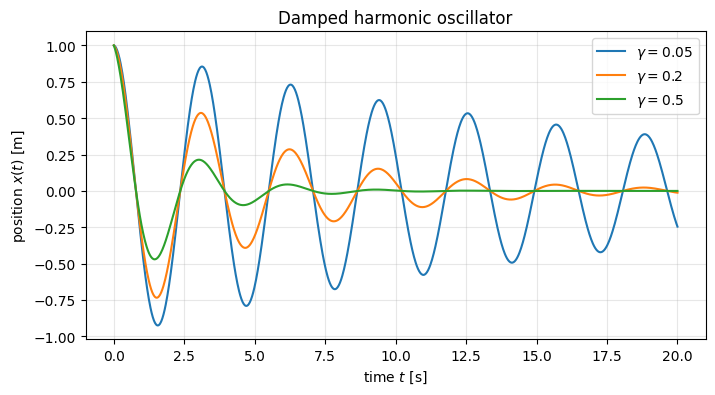

In [14]:
t = np.linspace(0, 20, 1000)
omega, A = 2.0, 1.0

fig, ax = plt.subplots(figsize=(8, 4))
for gamma in [0.05, 0.2, 0.5]:                     # one curve per damping rate
    ax.plot(t, A * np.exp(-gamma * t) * np.cos(omega * t), label=rf"$\gamma = {gamma}$")
ax.set_xlabel(r"time $t$ [s]")
ax.set_ylabel(r"position $x(t)$ [m]")
ax.set_title("Damped harmonic oscillator")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 2.4 Several panels
`plt.subplots(nrows, ncols)` returns an **array of axes**. Left: the trajectory $x(t)$; right: the **phase-space portrait** $(x, v)$.

`color="C0"`, `"C1"`, ... are the colours of Matplotlib's default colour cycle.

In the phase-space panel each turn of the curve is one oscillation; the curve spirals towards the origin $(0, 0)$ because damping removes energy and the amplitude shrinks.

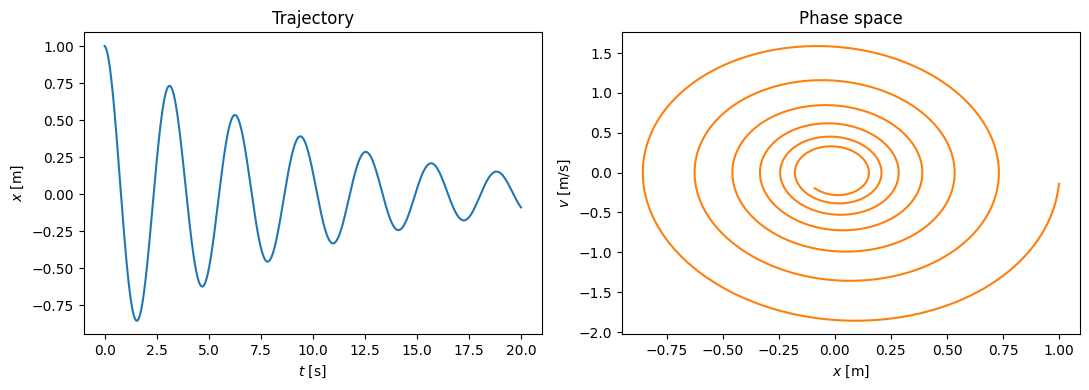

In [15]:
gamma = 0.1
x_t = A * np.exp(-gamma * t) * np.cos(omega * t)
v_t = np.gradient(x_t, t)            # numerical derivative dx/dt (central finite differences)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))   # 1 row, 2 columns

axes[0].plot(t, x_t, color="C0")
axes[0].set_xlabel("$t$ [s]"); axes[0].set_ylabel("$x$ [m]")
axes[0].set_title("Trajectory")

axes[1].plot(x_t, v_t, color="C1")
axes[1].set_xlabel("$x$ [m]"); axes[1].set_ylabel("$v$ [m/s]")
axes[1].set_title("Phase space")

fig.tight_layout()                   # avoid overlapping labels
plt.show()

### 2.5 Experimental data with error bars
Measured data are *points with uncertainties*, not lines. We simulate a noisy measurement and compare it with the model.
`np.random.default_rng(seed)` creates a random number generator; fixing the **seed** (any integer) makes the "random" numbers reproducible.

The noise is drawn with `rng.normal(size=n)`, which returns `n` numbers from the standard normal distribution (mean 0, standard deviation 1); multiplying them by $\sigma$ gives noise with standard deviation $\sigma$.
The noise level $\sigma$, 0.08 (8% of the amplitude), is visible but does not hide the oscillation.
In `ax.errorbar`, `yerr` is the half-length of each error bar and `fmt="o"` draws points without connecting lines.

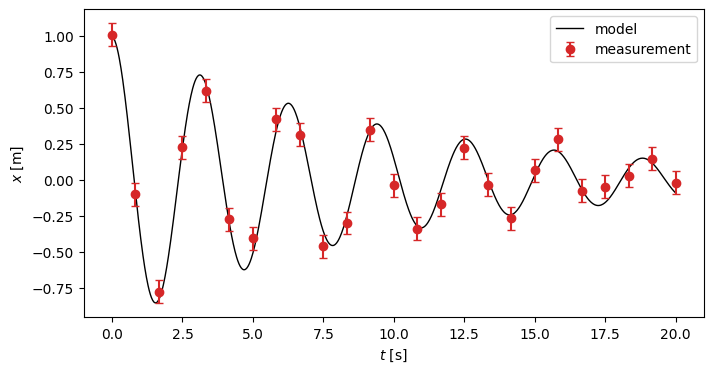

In [16]:
rng = np.random.default_rng(seed=0)

t_meas = np.linspace(0, 20, 25)                          # 25 measurement times
x_true = A * np.exp(-gamma * t_meas) * np.cos(omega * t_meas)
sigma = 0.08                                             # measurement uncertainty
x_meas = x_true + sigma * rng.normal(size=t_meas.size)   # add Gaussian noise

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, x_t, color="k", lw=1, label="model")
ax.errorbar(t_meas, x_meas, yerr=sigma, fmt="o", color="C3", capsize=3, label="measurement")
ax.set_xlabel("$t$ [s]"); ax.set_ylabel("$x$ [m]")
ax.legend()
plt.show()

### 2.6 Logarithmic axes
Exponential decay is a straight line on a **semi-log** plot; power laws are straight lines on a **log-log** plot.
The loss function of a neural network is usually plotted on a logarithmic scale, because it typically spans several orders of magnitude.

The time grid starts at 0.1 and not at 0: $t^{-2}$ diverges at zero, and the logarithm of zero cannot be drawn on a logarithmic axis.
`zip(a, b)` walks through two sequences in parallel and gives the pairs `(a[0], b[0])`, `(a[1], b[1])`, ...; here each panel is paired with the name of its scale.

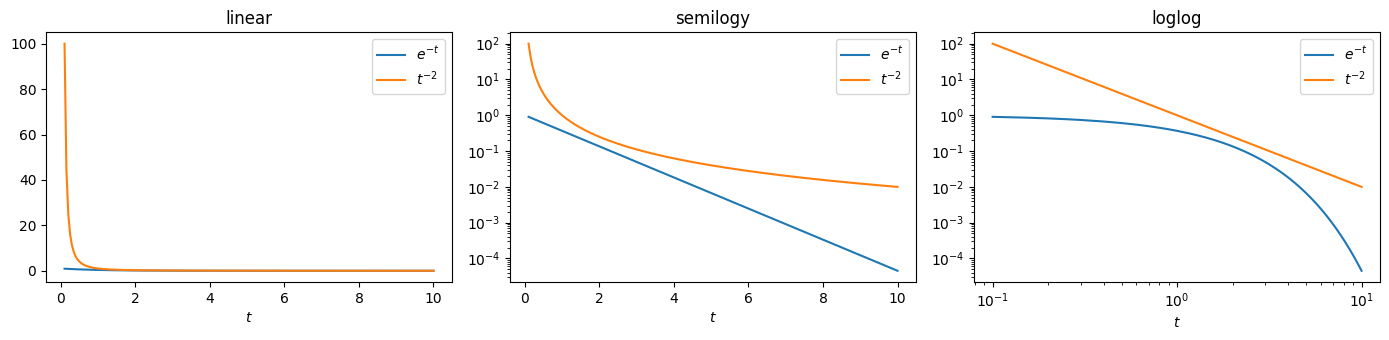

In [17]:
t_pos = np.linspace(0.1, 10, 200)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, scale in zip(axes, ["linear", "semilogy", "loglog"]):
    ax.plot(t_pos, np.exp(-t_pos), label=r"$e^{-t}$")
    ax.plot(t_pos, t_pos**-2.0, label=r"$t^{-2}$")
    if scale in ["semilogy", "loglog"]:
        ax.set_yscale("log")
    if scale == "loglog":
        ax.set_xscale("log")
    ax.set_title(scale)
    ax.set_xlabel("$t$")
    ax.legend()
fig.tight_layout()
plt.show()

### 2.7 Histograms
A histogram shows *how often* values occur — an estimate of a **probability distribution**.
`rng.normal(loc=0.0, scale=1.0, size=10_000)` draws samples with mean `loc` and standard deviation `scale`. (`10_000` is 10000; underscores only make long numbers readable.)
Estimating probability distributions from samples is one of the tasks of neural networks.

With `density=True` the bar heights are rescaled so that the total area of the histogram is 1. Only then can the histogram be compared with a probability density such as the Gaussian;
without it the bar heights are counts, which grow with the number of samples.
The number of bars, `bins=50`, is a compromise: too few bars hide the shape, while too many leave few samples in each bar and the histogram becomes noisy.
With 10 000 samples any value of order 30–100 works.

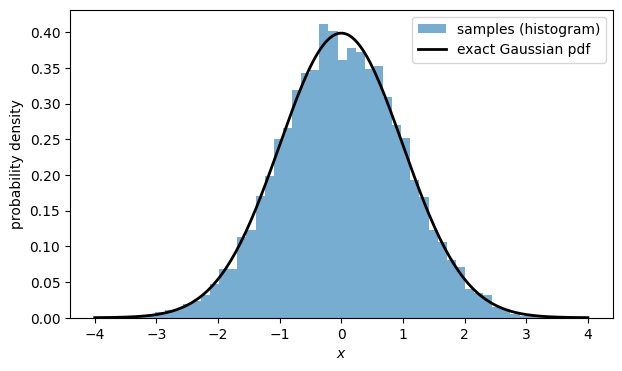

In [18]:
samples = rng.normal(loc=0.0, scale=1.0, size=10_000)   # 10 000 samples of N(0, 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(samples, bins=50, density=True, alpha=0.6, label="samples (histogram)")
xs = np.linspace(-4, 4, 200)
ax.plot(xs, np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi), "k", lw=2, label="exact Gaussian pdf")
ax.set_xlabel("$x$"); ax.set_ylabel("probability density")
ax.legend()
plt.show()

### 2.8 Functions of two variables
For a function $V(x, y)$ we need a 2D grid of points. `np.meshgrid(xg, yg)` builds it: it returns two 2D arrays `X` and `Y` of the same shape, which hold the $x$ and the $y$ coordinate
of every grid point. A formula in terms of `X` and `Y`, such as `(X**2 - 1)**2 + Y**2`, is then evaluated at all grid points at once.
Contour plots and colour maps of such grids will be our main tool to visualise **loss landscapes** $\mathcal{L}(\theta_1, \theta_2)$ when training neural networks.

Our example is a 2D double-well potential,
$$V(x,y) = (x^2 - 1)^2 + y^2 , \tag{3}$$
with minima at $(\pm 1, 0)$. Both grids have the same spacing (about 0.02), but different lengths (200 and 150 points),
so `X` and `Y` have the non-square shape (150, 200). This makes visible that **rows correspond to $y$ and columns to $x$**.

The figure shows the same function in three ways. `contourf` fills the regions between contour levels with colours, while `contour` draws only the lines, here at the levels 0.1, 0.5, 1 and 2.
`imshow`, in contrast, draws the array as an image, one pixel per array entry. By default it puts row 0 at the **top** (as in a photograph); `origin="lower"` puts row 0 (the smallest $y$) at the bottom,
as in a coordinate system, and `aspect="auto"` allows non-square pixels, so the image fills the panel.

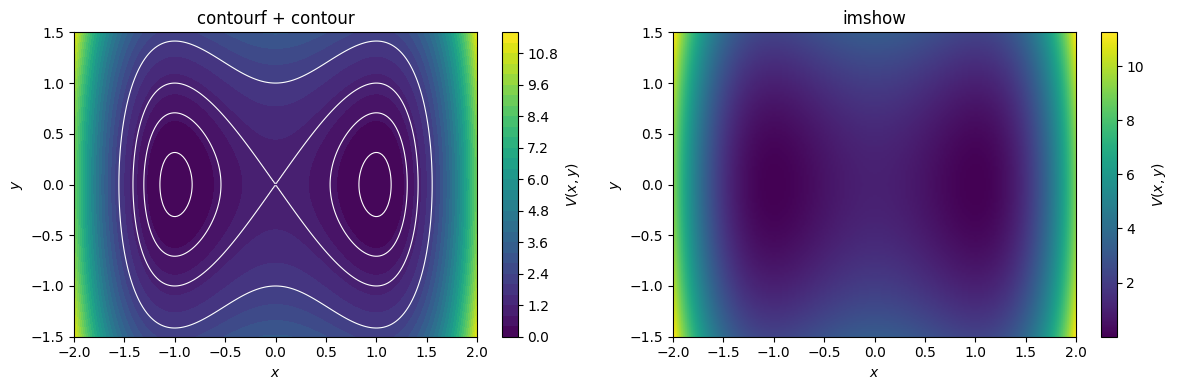

In [19]:
xg = np.linspace(-2, 2, 200)
yg = np.linspace(-1.5, 1.5, 150)
X, Y = np.meshgrid(xg, yg)          # X[i, j] = xg[j], Y[i, j] = yg[i]
V = (X**2 - 1)**2 + Y**2

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: filled contours + contour lines
cf = axes[0].contourf(X, Y, V, levels=30, cmap="viridis")
axes[0].contour(X, Y, V, levels=[0.1, 0.5, 1, 2], colors="white", linewidths=0.8)
fig.colorbar(cf, ax=axes[0], label="$V(x,y)$")
axes[0].set_title("contourf + contour")

# right: an image (each grid cell = one pixel); 'extent' sets the axis ranges
im = axes[1].imshow(V, origin="lower", extent=[xg[0], xg[-1], yg[0], yg[-1]], cmap="viridis", aspect="auto")
fig.colorbar(im, ax=axes[1], label="$V(x,y)$")
axes[1].set_title("imshow")

for ax in axes:
    ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
fig.tight_layout()
plt.show()

### 2.9 Saving a figure
Figures for reports should be saved as vector graphics (`.pdf`) or high-resolution `.png`; the format is chosen by the file extension.
`dpi` (dots per inch) sets the resolution of a `.png`, and `bbox_inches="tight"` trims empty margins. In Colab the files appear in the *Files* panel.

In [20]:
fig.savefig("double_well.png", dpi=200, bbox_inches="tight")   # raster image
fig.savefig("double_well.pdf", bbox_inches="tight")            # vector graphics
print("saved")

saved


<hr/>
## 3. Pandas: tables of data

Real data usually come as **tables**: each row is one measurement (one *sample*), each column one quantity (one *feature*).
This "samples × features" layout is exactly how data are fed to neural networks.
`pandas.DataFrame` is the standard Python tool for such tables.

### Measuring $g$ with a pendulum
For small amplitudes the period of a pendulum of length $L$ is
$$T = 2\pi\sqrt{\frac{L}{g}} \quad\Longrightarrow\quad T^2 = \frac{4\pi^2}{g}\,L . \tag{4}$$
Three student groups measured the period for six lengths, three repetitions each, with a timing uncertainty of 0.03 s; we simulate their data,
54 rows in total. One sample, one row of the table, is a single timing: the group that made it, the pendulum length $L$ in metres and the measured period $T$ in seconds.

In [21]:
import pandas as pd

rng = np.random.default_rng(seed=42)
g_true = 9.81
lengths = np.array([0.2, 0.4, 0.6, 0.8, 1.0, 1.2])        # [m]

rows = []                                                  # we collect rows as dictionaries
for group in ["A", "B", "C"]:
    for L in lengths:
        for repetition in range(3):                        # each measurement repeated 3 times
            T_exact = 2 * np.pi * np.sqrt(L / g_true)
            T_measured = T_exact + rng.normal(scale=0.03)   # timing uncertainty of one period ~ 0.03 s (e.g. from timing many periods)
            rows.append({"group": group, "L_m": L, "T_s": T_measured})

df = pd.DataFrame(rows)        # list of dicts -> table
df.head()                      # first 5 rows

,group,L_m,T_s
0,A,0.2,0.906282
1,A,0.2,0.865941
2,A,0.2,0.919654
3,A,0.4,1.296965
4,A,0.4,1.210217


### 3.1 A first look at the data
An analysis starts with the size of the data, the column names and basic statistics. In the output of `describe()`, `std` is the standard deviation and the rows `25%`, `50%`, `75%` are the quartiles: the values below which 25%, 50% and 75% of the entries lie
(`50%` is the median).

In [22]:
print("shape (rows, columns):", df.shape)
print("columns:", list(df.columns))
df.describe()                  # count, mean, std, min, quartiles, max of numeric columns

shape (rows, columns): (54, 3)
columns: ['group', 'L_m', 'T_s']


,L_m,T_s
count,54.000000,54.000000
mean,0.700000,1.621669
std,0.344772,0.447576
min,0.200000,0.865941
25%,0.400000,1.285848
50%,0.700000,1.669276
75%,1.000000,2.013079
max,1.200000,2.231405


### 3.2 Selecting columns and rows
A single column is selected by its name, `df["T_s"]`, and is returned as a `Series`.
Rows are selected with a condition, a **boolean mask**: `df[df["L_m"] > 1.0]`. The comparison `df["L_m"] > 1.0` gives a column of `True`/`False` values, one per row,
and `df[...]` with such a column keeps only the rows marked `True`.
Several conditions are combined with `&` (and) or `|` (or), each condition in its own parentheses.

In [23]:
df["T_s"].head(3)

0    0.906282
1    0.865941
2    0.919654
Name: T_s, dtype: float64

Rows of group B with a length of at least 1 m:

In [24]:
df[(df["group"] == "B") & (df["L_m"] >= 1.0)]

,group,L_m,T_s
30,B,1.0,2.070316
31,B,1.0,1.993874
32,B,1.0,1.990699
33,B,1.2,2.173123
34,B,1.2,2.216015
35,B,1.2,2.231405


### 3.3 Adding a computed column
Columns behave like NumPy arrays: arithmetic acts on all rows at once.

In [25]:
df["T2_s2"] = df["T_s"] ** 2                           # T^2
df["g_single"] = 4 * np.pi**2 * df["L_m"] / df["T2_s2"]  # g from each single measurement
df.head()

,group,L_m,T_s,T2_s2,g_single
0,A,0.2,0.906282,0.821347,9.613094
1,A,0.2,0.865941,0.749853,10.529636
2,A,0.2,0.919654,0.845763,9.335573
3,A,0.4,1.296965,1.682118,9.387788
4,A,0.4,1.210217,1.464625,10.781850


### 3.4 Grouping
The mean and standard deviation of $g$ for every group take one line:
`groupby("group")` splits the table into one sub-table per group, `["g_single"]` selects the column, and `agg` applies several summary functions at once to every sub-table.

Pandas and NumPy use different conventions for the standard deviation of $n$ values with mean $\bar x$:
$$s_{\rm pandas}=\sqrt{\frac{1}{n-1}\sum_i (x_i-\bar x)^2},\qquad s_{\rm NumPy}=\sqrt{\frac{1}{n}\sum_i (x_i-\bar x)^2}. \tag{5}$$
The first makes the *variance* estimate unbiased; the second is the default of `np.std`.
For small samples the two differ: for the numbers 1, 2, 3 pandas gives 1.0 and NumPy 0.816.

In [26]:
summary = df.groupby("group")["g_single"].agg(["mean", "std", "count"])
summary

,mean,std,count
group,,,
A,9.864675,0.402099,18
B,9.732202,0.277933,18
C,9.813299,0.278982,18


A single measurement scatters by about 0.3 m/s$^2$ (the `std` column). The mean of 18 measurements is more precise: its standard error is
$$\frac{\text{std}}{\sqrt{18}} \approx 0.07\text{–}0.1\ \text{m/s}^2 . \tag{6}$$
All three group means differ from the true value 9.81 by at most about 1.2 standard errors, i.e. they are consistent with it.

Grouping by two columns: the mean of $T^2$ for every combination of group and length.
`as_index=False` keeps `group` and `L_m` as ordinary columns; without it they would become the row labels (the *index*) of the result.

In [27]:
# average over repetitions for every (group, length) pair
per_length = df.groupby(["group", "L_m"], as_index=False)["T2_s2"].mean()
per_length.head(8)

,group,L_m,T2_s2
0,A,0.2,0.805654
1,A,0.4,1.552954
2,A,0.6,2.408240
3,A,0.8,3.248932
4,A,1.0,4.091384
5,A,1.2,4.765999
6,B,0.2,0.816652
7,B,0.4,1.620138


### 3.5 Plotting and fitting a line
$T^2$ is plotted against $L$ for each group, and one straight line,
$$T^2 = aL + b , \tag{7}$$
is fitted to all data with `np.polyfit`. By equation (4) the slope gives
$$g = \frac{4\pi^2}{a}. \tag{8}$$
(Fitting a straight line is the simplest example of what is later called *training a model*.)

We fit $T^2$ and not $T$, because by equation (4) $T^2$ is proportional to $L$, while $T$ grows as the square root of $L$.
`np.polyfit(x, y, deg=1)` finds the coefficients $a, b$ that minimise the sum of squared vertical distances (**least squares**),
$$\sum_i (y_i - a x_i - b)^2 ; \tag{9}$$
this sum is the simplest example of a **loss function**.
The fitted line is drawn from zero length to show the intercept $b$. Physically $b$ should be 0, so a value close to zero is a consistency check of the data.

`enumerate(...)` gives pairs (counter, element), and iterating over `df.groupby("group")` gives pairs (group name, sub-table).

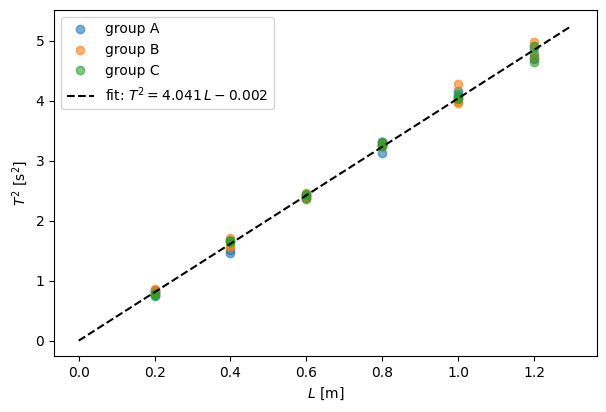

g from the fit: 9.769 m/s^2   (true value used in the simulation: 9.81)


In [28]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (group, sub) in enumerate(df.groupby("group")):        # loop over the sub-tables
    ax.plot(sub["L_m"], sub["T2_s2"], "o", alpha=0.6, color=f"C{i}", label=f"group {group}")

# one global linear fit to all data
a, b = np.polyfit(df["L_m"], df["T2_s2"], deg=1)               # returns [slope, intercept]
L_line = np.linspace(0, 1.3, 100)
ax.plot(L_line, a * L_line + b, "k--", label=f"fit: $T^2 = {a:.3f}\\,L {b:+.3f}$")

ax.set_xlabel("$L$ [m]"); ax.set_ylabel("$T^2$ [s$^2$]")
ax.legend()
plt.show()

g_fit = 4 * np.pi**2 / a
print(f"g from the fit: {g_fit:.3f} m/s^2   (true value used in the simulation: {g_true})")

### 3.6 Saving and loading CSV files
CSV ("comma separated values") is the most common plain-text data format.
`index=False` prevents pandas from writing the row numbers as an extra unnamed column, which would reappear as a column when the file is read back.

In [29]:
df.to_csv("pendulum.csv", index=False)        # write
df_loaded = pd.read_csv("pendulum.csv")       # read back
print(df_loaded.shape)                        # 5 columns: the 3 original ones and the 2 added in Section 3.3
# pd.read_csv also accepts a URL, e.g. pd.read_csv("https://.../data.csv")

(54, 5)


### 3.7 DataFrames and NumPy arrays
Neural networks take **arrays** as input, not tables; later in the course these arrays are converted to PyTorch tensors. `.to_numpy()` gives the raw numbers.

The brackets matter: `df["T_s"]` (one name) returns a one-column `Series`, which becomes a 1D array of shape `(n,)`.
`df[["L_m"]]` (a **list** of names, here with one element) returns a `DataFrame`, which becomes a 2D array of shape `(n, 1)`.
The inputs are kept 2D because a model may have several input columns (features).

In [30]:
X_data = df[["L_m"]].to_numpy()     # features: shape (n_samples, n_features)
y_data = df["T_s"].to_numpy()       # targets:  shape (n_samples,)
print(X_data.shape, y_data.shape)

(54, 1) (54,)


<hr/>
## 4. Classes and objects

In PyTorch a neural network is defined as a class, in the following form:
```python
class UATNet(nn.Module):
    def __init__(self, N, activation=torch.tanh):
        super().__init__()
        self.W1 = nn.Parameter(torch.randn(N))
        ...
    def forward(self, x):
        ...
model = UATNet(N=8)
y = model(x)
```
This is a network with one hidden layer (the network of the Universal Approximation Theorem from the lecture); here it is shown only to be read. `torch` and `nn` are PyTorch modules.
To read and write such code we need the basics of **object-oriented programming**: what a *class* and an *object* are, and what
`__init__`, `self`, `super()` and `forward` mean. 
### 4.1 Objects, attributes and methods
An **object** bundles *data* together with the *functions that act on that data*.
Data stored in an object are called **attributes**; they are accessed with a dot and no parentheses, as in `df.shape`.
Functions belonging to an object are called **methods**; they are called with a dot and parentheses, as in `df.head()`, `ax.plot(...)` or `fig.savefig(...)`.

The **type** (or **class**) of an object says what kind of object it is and which attributes and methods it has.

In [31]:
print(type(df))              # the DataFrame from Section 3 is an object of class DataFrame
print(df.shape)              # an attribute: data stored in the object
print(type(fig), type(ax))   # Matplotlib figures and axes are objects as well

s = "hello"                  # even a string is an object ...
print(s.upper())             # ... with methods
x_arr = np.array([3.0, 1.0, 2.0])
print(x_arr.shape, x_arr.max())   # a NumPy array: attribute .shape, method .max()

<class 'pandas.core.frame.DataFrame'>
(54, 5)
<class 'matplotlib.figure.Figure'> <class 'matplotlib.axes._axes.Axes'>
HELLO
(3,) 3.0


### 4.2 Defining a class
A **class** is a template; an **object** (also called an *instance*) is one concrete thing made from that template.
Consider a point particle in 2D with a mass, a position and a velocity. Every particle has these three pieces of data, but each particle has its own values.

The class is defined with the keyword `class`. Inside, functions defined with `def` become methods.
The method with the special name `__init__` (two underscores on each side) is the **constructor**: Python calls it automatically when a new object is created,
and its job is to store the initial data in the object.

In [32]:
class Particle:
    """A point particle in 2D."""

    def __init__(self, mass, position, velocity):
        # 'self' is the new object being created. Assigning to self.<name> creates an attribute,
        # i.e. stores the value INSIDE this particular object.
        self.mass = mass
        # dtype=float: store real numbers. Without it, [0, 0] would give an integer array: a fractional value
        # written into it later (position[0] = 0.5) would be silently truncated to 0, and position += 0.5 would fail.
        self.position = np.array(position, dtype=float)
        self.velocity = np.array(velocity, dtype=float)

# Creating objects: write the class name like a function call.
# Python creates an empty object, then calls __init__(new_object, 1.0, [0, 0], [1, 2]).
p1 = Particle(1.0, [0, 0], [1, 2])
p2 = Particle(5.0, [3, 1], [0, 0])

print(p1.mass, p1.position, p1.velocity)
print(p2.mass, p2.position, p2.velocity)      # p2 has its own, independent data
print(type(p1))

1.0 [0. 0.] [1. 2.]
5.0 [3. 1.] [0. 0.]
<class '__main__.Particle'>


The call `Particle(1.0, [0, 0], [1, 2])` passes three arguments, but `__init__` has four parameters.
The first one, `self`, is filled in by Python automatically with the object being created. Inside the class, `self` always means
"the object on which the method is working". The name `self` is a convention, not a keyword.

### 4.3 Methods
Methods are functions defined inside the class. They also receive the object as the first parameter `self`, so they can read and change its attributes.
The redefined class has two methods: the kinetic energy and a time step under a constant force.

In [33]:
class Particle:
    """A point particle in 2D."""

    def __init__(self, mass, position, velocity):
        self.mass = mass
        self.position = np.array(position, dtype=float)
        self.velocity = np.array(velocity, dtype=float)

    def kinetic_energy(self):
        """Return m v^2 / 2 of THIS particle."""
        return 0.5 * self.mass * np.sum(self.velocity**2)

    def step(self, force, dt):
        """Advance the state by one time step dt under the given force.
        Semi-implicit Euler step: first the velocity, then the position with the NEW velocity."""
        acceleration = force / self.mass
        self.velocity = self.velocity + acceleration * dt     # the attribute now refers to a new array (the object's state is updated)
        self.position = self.position + self.velocity * dt

p = Particle(2.0, [0, 0], [3, 4])
print("kinetic energy:", p.kinetic_energy())   # Python calls Particle.kinetic_energy(p)
# force = weight m*g of the 2 kg particle, pointing down; dt = 0.1 s is an arbitrary illustration value
p.step(force=np.array([0.0, -2.0 * 9.81]), dt=0.1)
print("after one step:", p.position, p.velocity)

kinetic energy: 25.0
after one step: [0.3    0.3019] [3.    3.019]


### 4.4 Many objects: a small simulation
Objects are convenient for many similar things, each with its own state: here five projectiles thrown at different angles, each a `Particle`.

Each projectile is advanced in a `while condition:` loop, which repeats the indented block as long as the condition is true; here, until the height $y$ of the projectile becomes negative.
The last stored point therefore lies slightly below the ground.
The position is stored with `p.position.copy()`: if the position were changed in place (e.g. `p.position += ...`), every stored entry without `.copy()` would change with it.

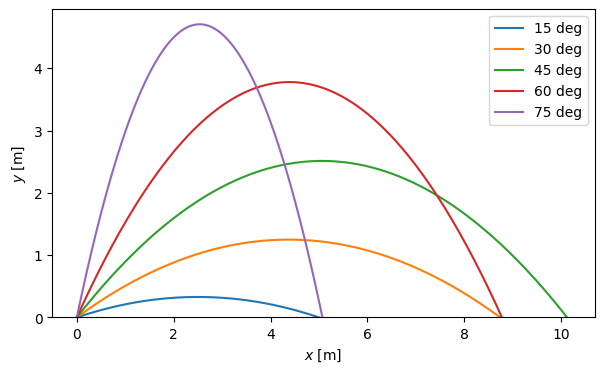

In [34]:
g_vec = np.array([0.0, -9.81])
angles_deg = [15, 30, 45, 60, 75]
projectiles = [Particle(1.0, [0, 0], [10 * np.cos(a), 10 * np.sin(a)])
               for a in np.deg2rad(angles_deg)]                       # a list of 5 objects

fig, ax = plt.subplots(figsize=(7, 4))
for i, p in enumerate(projectiles):
    path = [p.position.copy()]
    while p.position[1] >= 0:                    # until the projectile hits the ground
        p.step(force=p.mass * g_vec, dt=0.01)
        path.append(p.position.copy())
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], label=f"{angles_deg[i]} deg")
ax.set_xlabel("$x$ [m]"); ax.set_ylabel("$y$ [m]"); ax.set_ylim(0, None); ax.legend()
plt.show()

### 4.5 Special methods
Methods whose names start and end with two underscores have special meaning for Python; they are called automatically in certain situations:

| method | called when the code contains | used for |
|---|---|---|
| `__init__(self, ...)` | `Polynomial([1, 2])` | creating the object |
| `__repr__(self)` | `p` alone in the last line of a cell, or `print(p)` (print uses `__str__`, which defaults to `__repr__`) | a readable description |
| `__call__(self, x)` | `p(x)` | using an object like a function |
| `__add__(self, other)` | `p + q` | operator `+` (also `__mul__` for `*`, `__sub__` for `-`) |

As an example we store a polynomial
$$p(x) = c_0 + c_1x + c_2x^2 + \dots \tag{10}$$
as its list of coefficients.

A trailing `if` in a list comprehension, `[... for k, ck in enumerate(self.c) if ck != 0]`, keeps only the elements satisfying the condition, and `np.pad(a, (0, m))` appends `m` zeros at the end of `a`.

In [35]:
class Polynomial:
    """Polynomial c[0] + c[1] x + c[2] x^2 + ... ."""

    def __init__(self, coefficients):
        self.c = np.array(coefficients, dtype=float)

    def __repr__(self):
        terms = [f"{ck:+g} x^{k}" for k, ck in enumerate(self.c) if ck != 0]
        return "Polynomial(" + " ".join(terms) + ")"

    def __call__(self, x):
        """Evaluate the polynomial at x (a number or an array)."""
        return sum(ck * x**k for k, ck in enumerate(self.c))

    def __add__(self, other):
        """Sum of two polynomials: add the coefficients (the shorter list is padded with zeros)."""
        n = max(len(self.c), len(other.c))
        a = np.pad(self.c, (0, n - len(self.c)))
        b = np.pad(other.c, (0, n - len(other.c)))
        return Polynomial(a + b)                    # a NEW object is returned

p = Polynomial([1, 0, -2])      # 1 - 2 x^2
q = Polynomial([0, 3])          # 3 x
print(p)                        # uses __repr__
print(p + q)                    # uses __add__
print(p(2.0))                   # uses __call__: 1 - 2*4 = -7
print((p + q)(np.array([0.0, 1.0, 2.0])))   # works on arrays as well

Polynomial(+1 x^0 -2 x^2)
Polynomial(+1 x^0 +3 x^1 -2 x^2)
-7.0
[ 1.  2. -1.]


`__call__` is the reason why in PyTorch we write `model(x)` and not `model.forward(x)`: calling the object runs its `__call__`,
which (after some bookkeeping) calls `forward`. `__add__` and `__mul__` can, for example, be used to build *dual numbers*, which perform automatic differentiation.

### 4.6 Inheritance
A class can be built on top of another class: it **inherits** all attributes and methods of the *parent* (base) class and can add new ones or replace existing ones.
The parent is given in parentheses after the class name.

A charged particle, for instance, is a particle with an extra attribute `charge` and an extra method for the force in an electric field.
Its constructor must still set mass, position and velocity. Instead of repeating that code, it calls the constructor of the parent class with
`super().__init__(...)` (`super()` means "the parent class"), and then adds its own attribute.
`isinstance(obj, C)` returns `True` if `obj` is an object of class `C` or of a class that inherits from `C`.

In [36]:
class ChargedParticle(Particle):            # ChargedParticle inherits from Particle
    """A Particle with an electric charge."""

    def __init__(self, mass, position, velocity, charge):
        super().__init__(mass, position, velocity)   # let Particle.__init__ store mass, position, velocity
        self.charge = charge                         # then add what is new

    def electric_force(self, E_field):
        return self.charge * np.array(E_field, dtype=float)

e = ChargedParticle(1.0, [0, 0], [1, 0], charge=-1.0)
print(e.mass, e.charge)                    # attributes from both classes
print(e.kinetic_energy())                  # method inherited from Particle
print(e.electric_force([0.0, 2.0]))        # new method (-0. = negative zero: -1.0 * 0.0)
print(isinstance(e, Particle))             # a ChargedParticle IS a Particle

1.0 -1.0
0.5
[-0. -2.]
True


If we forgot `super().__init__(...)`, the attributes `mass`, `position`, `velocity` would never be created and `e.kinetic_energy()` would fail
with `AttributeError`. The same happens in PyTorch: a network class that forgets `super().__init__()` raises an error as soon as it tries to store a layer.

### 4.7 A gas of hard disks in a closed box
A larger example combines two classes. `Disk` is a `Particle` with a radius: it **inherits** mass, position, velocity and `kinetic_energy` from `Particle` (Section 4.6) and adds a method `move` for free flight.
`Box` holds a list of disks and implements the dynamics: free flight, elastic reflection at the walls and elastic collisions between disks.
It also records the momentum transferred to the walls, from which the **pressure** follows.

In an elastic collision of two disks only the velocity components along the line joining the centres change. The unit vector along this line, pointing from disk a to disk b, and the relative velocity along it are
$$\mathbf n = \frac{\mathbf r_b-\mathbf r_a}{|\mathbf r_b-\mathbf r_a|}, \tag{11}$$
$$v_{\rm rel} = (\mathbf v_a - \mathbf v_b)\cdot\mathbf n . \tag{12}$$
When $v_{\rm rel}$ is positive (the disks approach each other), the momentum
$$J = \frac{2 v_{\rm rel}}{1/m_a + 1/m_b} \tag{13}$$
is exchanged:
$$\mathbf v_a \leftarrow \mathbf v_a - (J/m_a)\,\mathbf n,\qquad \mathbf v_b \leftarrow \mathbf v_b + (J/m_b)\,\mathbf n . \tag{14}$$
This conserves momentum and kinetic energy.

The collisions are found without a loop over pairs. The array `pos` has shape `(n, 2)`; `pos[:, None, :]` has shape `(n, 1, 2)` and `pos[None, :, :]` shape `(1, n, 2)`, because `None` inserts a new axis of length 1.
Their difference is broadcast to shape `(n, n, 2)`, and entry `[i, j]` is the vector $\mathbf r_i - \mathbf r_j$: all pairwise differences at once.
Squaring and summing over the last axis (`axis=-1`, the two coordinates) gives the squared distances, an `(n, n)` array.
The comparison `dist < 2 * radius` then marks overlapping pairs. `np.triu(..., k=1)` keeps only the entries above the diagonal, which removes the distance of each disk to itself (zero)
and counts each pair $(i, j)$ only once, and `np.nonzero` returns the row and column indices of the remaining `True` entries.

Collisions are detected only after the disks overlap a little. For this reason the velocity is changed only if the disk moves **into** the wall (`d.velocity[axis] < 0` at the left wall),
or if the two disks approach each other (`v_rel > 0`). A disk may still overlap after the reflection; without these conditions its velocity would be reversed again in the next step
and the disk would stick to the wall or to its partner.

In [37]:
class Disk(Particle):
    """A Particle with a finite radius (a hard disk)."""

    def __init__(self, mass, position, velocity, radius):
        super().__init__(mass, position, velocity)
        self.radius = radius

    def move(self, dt):
        """Free flight (no force) for a time dt."""
        self.position = self.position + self.velocity * dt


class Box:
    """A square box [0, L] x [0, L] containing hard disks that collide elastically."""

    def __init__(self, L, disks):
        self.L = L
        self.disks = disks
        self.time = 0.0
        self.wall_impulse = 0.0          # total momentum transferred to the walls (for the pressure)

    def collide_with_walls(self):
        for d in self.disks:
            for axis in range(2):        # axis 0 = x, axis 1 = y
                if d.position[axis] < d.radius and d.velocity[axis] < 0:            # hits the left/bottom wall
                    d.velocity[axis] *= -1
                    self.wall_impulse += 2 * d.mass * abs(d.velocity[axis])
                elif d.position[axis] > self.L - d.radius and d.velocity[axis] > 0:  # hits the right/top wall
                    d.velocity[axis] *= -1
                    self.wall_impulse += 2 * d.mass * abs(d.velocity[axis])

    def collide_pairs(self):
        # positions of all disks as one array, so that all distances are computed at once with NumPy
        pos = np.array([d.position for d in self.disks])
        dist = np.sqrt(np.sum((pos[:, None, :] - pos[None, :, :])**2, axis=-1))
        i_idx, j_idx = np.nonzero(np.triu(dist < 2 * self.disks[0].radius, k=1))   # pairs i < j that overlap
        for i, j in zip(i_idx, j_idx):
            a, b = self.disks[i], self.disks[j]
            n = (b.position - a.position) / dist[i, j]          # unit vector from a to b
            v_rel = np.dot(a.velocity - b.velocity, n)          # approach speed along n
            if v_rel > 0:                                       # only if the disks move towards each other
                # elastic collision: exchange of momentum along the line of centres
                J = 2 * v_rel / (1 / a.mass + 1 / b.mass)
                a.velocity = a.velocity - J / a.mass * n
                b.velocity = b.velocity + J / b.mass * n

    def step(self, dt):
        for d in self.disks:
            d.move(dt)
        self.collide_with_walls()
        self.collide_pairs()
        self.time += dt

    def speeds(self):
        return np.array([np.linalg.norm(d.velocity) for d in self.disks])

    def kinetic_energy(self):
        return sum(d.kinetic_energy() for d in self.disks)

We place 64 disks on a regular grid and give them **all the same unit speed** in random directions. Collisions redistribute the energy, and the speeds
should approach the equilibrium **Maxwell–Boltzmann distribution**, which in two dimensions reads
$$f(v) = \frac{m v}{k_B T}\,\exp\!\Big(-\frac{m v^2}{2 k_B T}\Big), \tag{15}$$
with the temperature given, in 2D and per particle, by
$$k_B T = \langle \tfrac12 m v^2\rangle . \tag{16}$$
We use units in which $k_B$ and $m$ are one. Equation (16) is equipartition: each of the two velocity components contributes half of $k_BT$.

64 disks of radius 0.15 in a $10\times10$ box cover 4.5% of the area: a dilute gas, close to an ideal gas but with a visible effect of the finite disk size; other values with a small area fraction behave similarly.
The time step $\Delta t$, 0.01, moves a disk with speed of order 1 by about 0.01 per step, much less than the disk diameter 0.3, so two disks cannot jump over each other between two checks.
If $v\,\Delta t$ became comparable to the diameter, collisions would be missed.
The equilibration lasts 3000 steps (30 time units). In this time each disk collides about 15 times (counted in a separate run), while a few collisions per disk already randomise the speeds,
so the value is a generous margin, not a precise requirement. The 6000 measurement steps (60 time units) only collect more data for the histogram.

Speeds are recorded only every 20 steps, because consecutive steps are almost identical; this still gives 300 records of 64 disks, 19 200 speed values.
Snapshots for the animation are stored every 25 steps during the first 1500 steps (15 time units), 61 frames in total.

In [38]:
rng = np.random.default_rng(0)
L_box, n_side, radius = 10.0, 8, 0.15
disks = []
for ix in range(n_side):
    for iy in range(n_side):
        angle = rng.uniform(0, 2 * np.pi)                       # random direction, speed 1
        disks.append(Disk(mass=1.0, position=[(ix + 0.5) * L_box / n_side, (iy + 0.5) * L_box / n_side],
                          velocity=[np.cos(angle), np.sin(angle)], radius=radius))
box = Box(L_box, disks)

E_start = box.kinetic_energy()
speeds_start = box.speeds()
snapshots = [np.array([d.position for d in box.disks])]       # positions for the animation below
for step in range(3000):                                      # equilibration: 30 time units
    box.step(dt=0.01)
    if step < 1500 and step % 25 == 0:                        # first 15 time units, every 25 steps
        snapshots.append(np.array([d.position for d in box.disks]))
print(f"kinetic energy: start {E_start:.6f}, after 3000 steps {box.kinetic_energy():.6f}")

# measurement phase: collect speeds and the momentum transferred to the walls
box.wall_impulse = 0.0          # reset the momentum counter
t_start = box.time
speeds_eq = []
for step in range(6000):
    box.step(dt=0.01)
    if step % 20 == 0:
        speeds_eq.extend(box.speeds())
speeds_eq = np.array(speeds_eq)

kinetic energy: start 32.000000, after 3000 steps 32.000000


The speed distribution after the collisions is compared with the Maxwell–Boltzmann formula, and the pressure measured at the walls with the ideal-gas value.

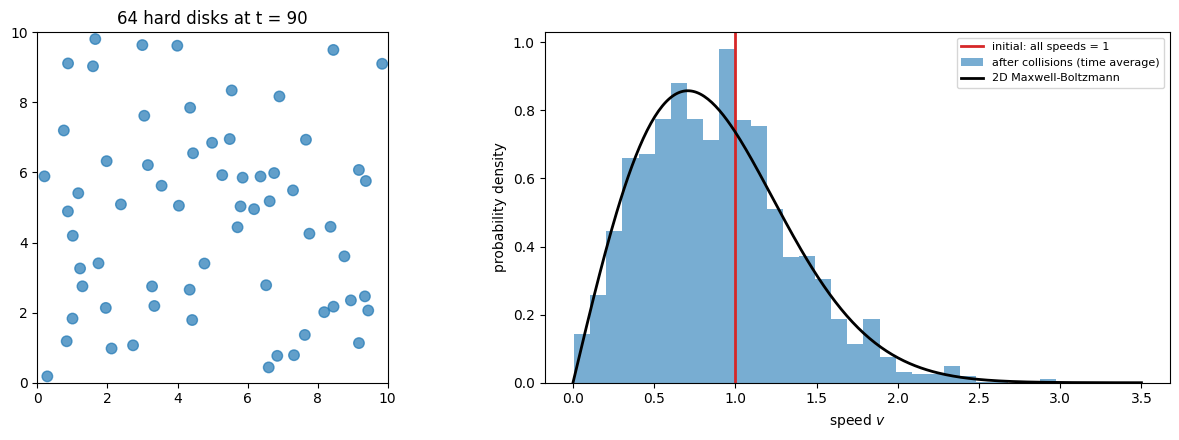

measured pressure            P = 0.3627
ideal gas (point particles)  P = N kT / A = 0.3200
ratio P A / (N kT)             = 1.134


In [39]:
N = len(box.disks)
kT = box.kinetic_energy() / N                       # 2D: <m v^2 / 2> = k_B T per particle
v = np.linspace(0, 3.5, 300)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# left: one snapshot of the box
pos = np.array([d.position for d in box.disks])
for p_xy in pos:
    axes[0].add_patch(plt.Circle(p_xy, radius, color="C0", alpha=0.7))
axes[0].set_xlim(0, L_box); axes[0].set_ylim(0, L_box); axes[0].set_aspect("equal")
axes[0].set_title(f"{N} hard disks at t = {box.time:.0f}")
# right: speed distribution before and after
axes[1].axvline(1.0, color="C3", lw=2, label="initial: all speeds = 1")
axes[1].hist(speeds_eq, bins=30, density=True, alpha=0.6, label="after collisions (time average)")
axes[1].plot(v, v / kT * np.exp(-v**2 / (2 * kT)), "k", lw=2, label="2D Maxwell-Boltzmann")
axes[1].set_xlabel("speed $v$"); axes[1].set_ylabel("probability density"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

# pressure = momentum transferred to the walls per unit time and unit wall length (perimeter 4L)
P = box.wall_impulse / ((box.time - t_start) * 4 * L_box)
print(f"measured pressure            P = {P:.4f}")
print(f"ideal gas (point particles)  P = N kT / A = {N * kT / L_box**2:.4f}")
print(f"ratio P A / (N kT)             = {P * L_box**2 / (N * kT):.3f}")

The speeds relax from a single value to the Maxwell–Boltzmann distribution: collisions alone produce thermal equilibrium. The pressure is close to the ideal-gas value
$$P = \frac{N k_B T}{A} \tag{17}$$
but somewhat larger, because the disks have a finite size: they exclude part of the area from each other and from the walls. Repeating the simulation with
smaller disks (e.g. `radius = 0.05`) brings the ratio closer to 1.

The stored snapshots show the beginning of the equilibration (the first 15 time units) as an animation.
`FuncAnimation(fig, update, frames=n, ...)` calls `update(frame)` for `frame = 0, 1, ..., n-1`, and `anim.to_jshtml(...)` turns the animation into an HTML player.

In [40]:
from matplotlib import animation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(4, 4), dpi=60)
ax.set_xlim(0, L_box); ax.set_ylim(0, L_box); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
circles = [plt.Circle(xy, radius, color="C0", alpha=0.7) for xy in snapshots[0]]
for c in circles:
    ax.add_patch(c)

def update(frame):
    for c, xy in zip(circles, snapshots[frame]):
        c.center = xy                      # move every circle to its position in this frame
    return circles

anim = animation.FuncAnimation(fig, update, frames=len(snapshots), interval=50, blit=True)
plt.close(fig)
HTML(anim.to_jshtml(default_mode="once"))

### 4.8 Structure of a PyTorch model
`torch.nn.Module` is a base class with a lot of machinery. Its idea is visible in a **simplified imitation in plain Python and NumPy**; this is *not* PyTorch code,
it only reproduces the structure. A class `Parameter` marks an array as a trainable parameter. `Module.__call__` calls `forward`, so that `model(x)` works.
`Module.parameters()` collects all attributes that are `Parameter`s, which is how an optimiser finds the numbers it has to change:
`vars(self)` is a dictionary of all attributes of the object (name → value), and `isinstance(v, Parameter)` keeps only the `Parameter` objects.

The input `x` holds `B` points (shape `(B,)`; `B` stands for *batch*, the number of points evaluated at once), and `x[:, None]` inserts a new axis and gives shape `(B, 1)`.
Multiplied by `W1` of shape `(N,)`, broadcasting gives a `(B, N)` table whose entry `[k, i]` is the input of neuron $i$ at point $k$,
$$z_{ki} = W_{1,i}\,x_k + b_i . \tag{18}$$
The operator `@` is matrix multiplication: `hidden @ W2` with shapes `(B, N) @ (N,)` gives shape `(B,)`, the output for every point,
$$y_k = \sum_i W_{2,i}\,\sigma(z_{ki}) . \tag{19}$$

`W2` is divided by $\sqrt N$. The output is a sum of $N$ terms; if every $W_{2,i}$ has the variance $1/N$, the variance of the sum is of order 1 for every $N$,
so the initial output does not grow with the size of the network. `W1` and `b` are not rescaled, because each hidden neuron receives a single input $x$,
whose scale does not depend on $N$.
The generator `default_rng(0)` is created inside the constructor, so every `UATNet` with the same `N` starts from the same weights. This makes the example reproducible;
a real model would draw different random weights each time.

In [41]:
class Parameter:
    """Imitation of nn.Parameter: a container for an array that should be trained."""
    def __init__(self, value):
        self.value = np.array(value, dtype=float)

class Module:
    """Imitation of nn.Module (greatly simplified)."""
    def __init__(self):
        pass                                     # the real nn.Module sets up internal bookkeeping here

    def __call__(self, x):
        return self.forward(x)                   # model(x) -> model.forward(x)

    def parameters(self):
        # look through all attributes of the object and keep those that are Parameters
        return [v for v in vars(self).values() if isinstance(v, Parameter)]

class UATNet(Module):
    """f(x) = sum_i W2_i * sigma(W1_i x + b_i) + c  -- the network of the Universal Approximation Theorem."""

    def __init__(self, N, activation=np.tanh):
        super().__init__()                                    # 1. set up the base class
        rng = np.random.default_rng(0)
        self.W1 = Parameter(rng.normal(size=N))               # 2. trainable parameters, stored as attributes
        self.b = Parameter(rng.normal(size=N))
        self.W2 = Parameter(rng.normal(size=N) / np.sqrt(N))
        self.c = Parameter(np.zeros(1))
        self.activation = activation                          # 3. a plain attribute (not trained)

    def forward(self, x):
        # x has shape (B,); hidden has shape (B, N): neuron i evaluated at every input point
        hidden = self.activation(self.W1.value * x[:, None] + self.b.value)
        return hidden @ self.W2.value + self.c.value

net = UATNet(N=5)
x = np.linspace(-3, 3, 7)
print("net(x) =", net(x).round(3))                          # __call__ -> forward
print("number of Parameter objects:", len(net.parameters()))
print("number of trainable numbers:", sum(p.value.size for p in net.parameters()))

net(x) = [ 0.694  0.499  0.055 -0.314 -0.487 -0.562 -0.605]
number of Parameter objects: 4
number of trainable numbers: 16


Line by line, the PyTorch version has the same structure:

| line | meaning |
|---|---|
| `class UATNet(nn.Module):` | define a new class that inherits from PyTorch's `nn.Module` |
| `def __init__(self, N, activation=torch.tanh):` | the constructor; `N` and `activation` are chosen when the object is created |
| `super().__init__()` | run the constructor of `nn.Module` first (it prepares the bookkeeping of parameters) |
| `self.W1 = nn.Parameter(torch.randn(N))` | create a tensor of $N$ random numbers, mark it as trainable, store it in the object |
| `self.activation = activation` | store a function in the object (not a trainable parameter) |
| `def forward(self, x):` | describe how the output is computed from the input, using the stored parameters |
| `model = UATNet(N=8)` | create one network (an object) with eight hidden neurons |
| `model(x)` | evaluate it; `nn.Module.__call__` calls `forward` |
| `model.parameters()` | all trainable tensors; passed to an optimiser, e.g. `torch.optim.Adam(model.parameters())` |

<hr/>
## 5. Summary

The Python basics of Section 1 — variables, formatted output with `f"{x:.3f}"`, lists indexed from 0, `for` loops, `if`, functions with docstrings and dictionaries — are the vocabulary of every later notebook.
For figures we prefer the object-oriented interface `fig, ax = plt.subplots()`, always label axes **with units**, add legends, and use logarithmic scales, histograms, and `contourf` or `imshow` for 2D data.
Pandas provides the `DataFrame` with `head` and `describe` for a first look, boolean masks for selection, computed columns, `groupby`, `to_csv`/`read_csv`, and `.to_numpy()` to hand the numbers to a model.
Data for machine learning are tables of shape **(samples, features)**.

Objects bundle data (**attributes**, `obj.x`) with functions (**methods**, `obj.f()`); a **class** is the template, and `obj = ClassName(...)` creates an object.
`__init__` stores the initial data, `self` is the object itself, and the special methods `__repr__`, `__call__` and `__add__` define printing, calling and `+`.
With inheritance, `class B(A)`, the class B gets everything from A, and `super().__init__(...)` runs the constructor of A. PyTorch networks are exactly such classes: they inherit from `nn.Module` and define `__init__` and `forward`.

<hr/>
## 6. Exercises

Each exercise is followed by a solution.

### Exercise 1 — Standing waves
Plot the first four standing-wave modes of a string of unit length $L$,
$$y_n(x) = \sin(n\pi x / L),\qquad n=1,\dots,4, \tag{20}$$
in a $2\times2$ grid of panels. Each panel: title `n = ...`, axis labels, a horizontal line at zero.
*Hint:* `axes.flatten()` turns the 2×2 array of axes into a list of 4.

#### Solution

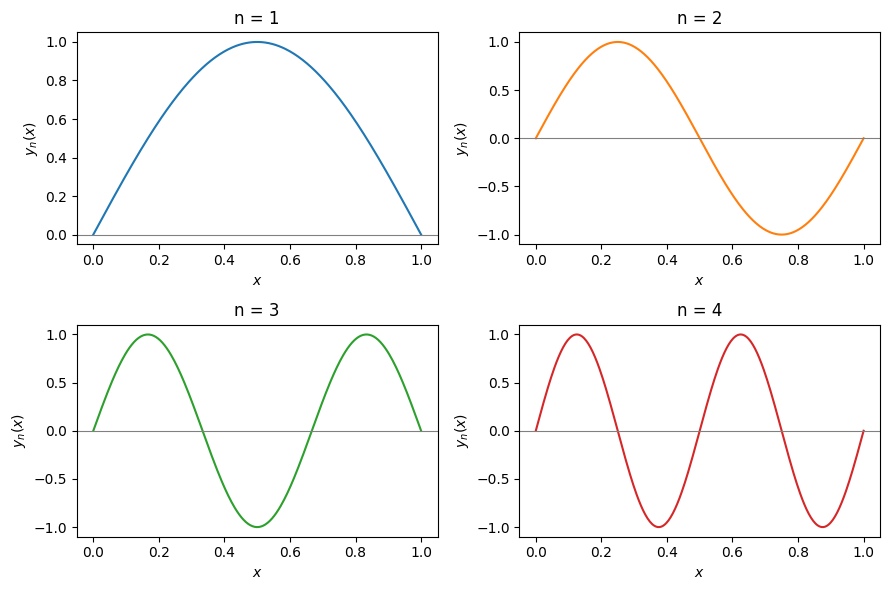

In [42]:
L = 1.0                                   # length of the string
x = np.linspace(0, L, 300)                # 300 points along the string

# plt.subplots(2, 2) returns a 2x2 array of panels; .flatten() makes it a list of 4 panels
fig, axes = plt.subplots(2, 2, figsize=(9, 6))

# zip pairs n = 1, 2, 3, 4 with the four panels: in each loop step we draw one mode into one panel
for n, ax in zip(range(1, 5), axes.flatten()):
    y_n = np.sin(n * np.pi * x / L)       # n-th standing wave
    ax.plot(x, y_n, color=f"C{n-1}")      # C0, C1, ... are matplotlib's default colours
    ax.axhline(0, color="gray", lw=0.8)   # reference line y = 0 (the nodes lie on it)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y_n(x)$")

fig.tight_layout()                        # avoid overlapping titles and labels
plt.show()

### Exercise 2 — Black-body radiation
Planck's law for the spectral radiance:
$$B(\lambda, T) = \frac{2hc^2}{\lambda^5}\,\frac{1}{e^{hc/(\lambda k_B T)} - 1}. \tag{21}$$
1. Write a function `planck(lam, T)` in SI units, with
$$h = 6.626\times10^{-34},\qquad c=2.998\times10^{8},\qquad k_B = 1.381\times10^{-23}. \tag{22}$$
2. Plot $B(\lambda,T)$ for the temperatures 3000, 4000, 5000 and 6000 K on wavelengths from 100 to 3000 nm (put **nm** on the x-axis).
3. For every $T$ find numerically the wavelength of the maximum (`np.argmax`) and check **Wien's law**,
$$\lambda_{\max} T \approx 2.898\times10^{-3}\ \text{m·K}. \tag{23}$$
4. Make a second figure with a logarithmic y-axis and describe the behaviour at short wavelengths.

#### Solution

T = 3000 K: lambda_max =   966.1 nm,  lambda_max*T = 2.8982e-03 m K
T = 4000 K: lambda_max =   723.8 nm,  lambda_max*T = 2.8952e-03 m K
T = 5000 K: lambda_max =   578.7 nm,  lambda_max*T = 2.8937e-03 m K
T = 6000 K: lambda_max =   483.0 nm,  lambda_max*T = 2.8979e-03 m K


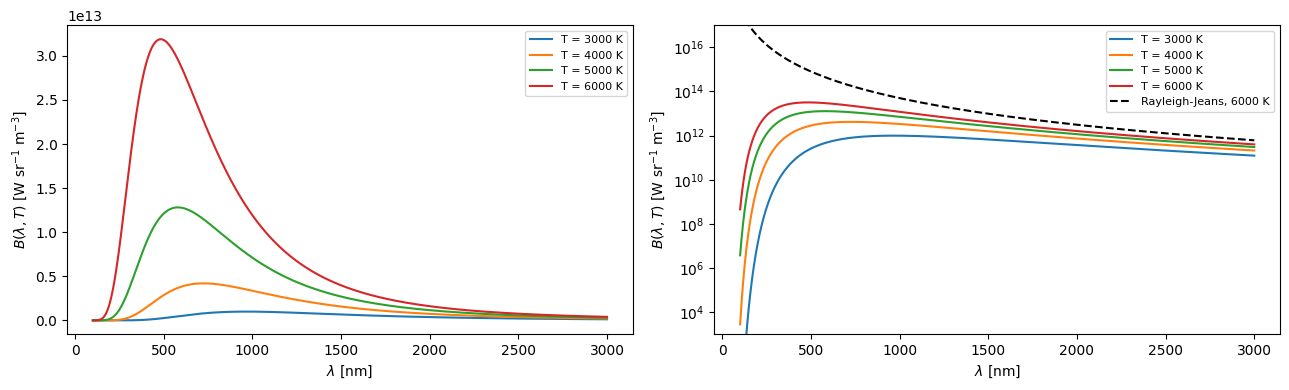

In [43]:
# Physical constants in SI units
h, c, kB = 6.626e-34, 2.998e8, 1.381e-23

def planck(lam, T):
    """Spectral radiance B(lambda, T); lam in metres, T in kelvin."""
    return 2 * h * c**2 / lam**5 / (np.exp(h * c / (lam * kB * T)) - 1)

def rayleigh_jeans(lam, T):
    """Classical limit of Planck's law (valid for long wavelengths).
    It follows from Planck's law with e^x - 1 ~ x for x = hc/(lambda kB T) << 1."""
    return 2 * c * kB * T / lam**4

# wavelengths in METRES (the formula needs SI units). The spacing is 1.45 nm, so lambda_max found by argmax
# is accurate to about 1 nm, i.e. about 0.1% in lambda_max * T.
lam = np.linspace(100e-9, 3000e-9, 2000)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for T in [3000, 4000, 5000, 6000]:
    B = planck(lam, T)

    # Wien's law check: np.argmax gives the INDEX of the largest value; lam[index] is the wavelength there
    lam_max = lam[np.argmax(B)]
    print(f"T = {T} K: lambda_max = {lam_max*1e9:7.1f} nm,  lambda_max*T = {lam_max*T:.4e} m K")

    # we plot against lam*1e9, i.e. in nanometres, which is easier to read
    axes[0].plot(lam * 1e9, B, label=f"T = {T} K")
    axes[1].plot(lam * 1e9, B, label=f"T = {T} K")

# on the log plot we also show the classical Rayleigh-Jeans law for T = 6000 K
axes[1].plot(lam * 1e9, rayleigh_jeans(lam, 6000), "k--", label="Rayleigh-Jeans, 6000 K")
axes[1].set_yscale("log")
axes[1].set_ylim(1e3, 1e17)   # B at 3000 K falls to ~1e-2 at 100 nm; the lower limit cuts off this uninteresting range

for ax in axes:
    ax.set_xlabel(r"$\lambda$ [nm]")
    ax.set_ylabel(r"$B(\lambda, T)$ [W sr$^{-1}$ m$^{-3}$]")
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

# All products lambda_max * T are close to 2.898e-3 m K (Wien's displacement law).
# On the log scale Planck's law falls off exponentially at short wavelengths, while the classical
# Rayleigh-Jeans law grows like 1/lambda^4 without bound ("ultraviolet catastrophe").
# The two agree only at long wavelengths.

### Exercise 3 — Projectile experiment
1. Build a DataFrame with columns `angle_deg`, `v0` and `range_m` for angles $10^\circ, 20^\circ, \dots, 80^\circ$ and the initial speeds 10, 15 and 20 m/s,
   where the range (no air resistance) is
$$R = \frac{v_0^2 \sin(2\alpha)}{g}. \tag{24}$$
   Add Gaussian noise with standard deviation 0.2 m to mimic a measurement.
2. Using `groupby("v0")`, find for each $v_0$ the angle with the largest measured range (*hint:* `df.loc[sub["range_m"].idxmax()]`).
3. Plot range vs. angle, one curve per $v_0$, with a legend.

#### Solution

   angle_deg  v0    range_m
0         10  10   3.555561
1         20  10   6.716695
2         30  10   8.894073
3         40  10   9.778184
4         50  10  10.219886
v0 = 10 m/s: best angle = 50.0 deg, range = 10.22 m
v0 = 15 m/s: best angle = 40.0 deg, range = 22.70 m
v0 = 20 m/s: best angle = 50.0 deg, range = 40.16 m


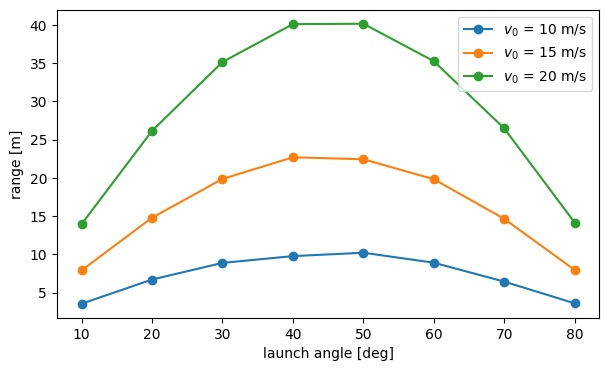

In [44]:
rng = np.random.default_rng(1)          # random generator with a fixed seed -> reproducible noise
g_earth = 9.81

# collect one dictionary per measurement in a list ...
rows = []
for v0 in [10, 15, 20]:                         # initial speeds [m/s]
    for angle in range(10, 90, 10):             # 10, 20, ..., 80 degrees
        alpha = np.deg2rad(angle)               # trigonometric functions need radians
        R_exact = v0**2 * np.sin(2 * alpha) / g_earth
        R_measured = R_exact + rng.normal(scale=0.2)     # add measurement noise, std 0.2 m
        rows.append({"angle_deg": angle, "v0": v0, "range_m": R_measured})

# ... and turn the list of dictionaries into a table
df_proj = pd.DataFrame(rows)
print(df_proj.head())

# for each v0, the row with the largest range
# groupby("v0") splits the table into sub-tables; idxmax() returns the row label of the maximum,
# and df_proj.loc[label] selects that row.
for v0, sub in df_proj.groupby("v0"):
    best = df_proj.loc[sub["range_m"].idxmax()]
    print(f"v0 = {v0} m/s: best angle = {best['angle_deg']} deg, range = {best['range_m']:.2f} m")

# one curve per v0
fig, ax = plt.subplots(figsize=(7, 4))
for v0, sub in df_proj.groupby("v0"):
    ax.plot(sub["angle_deg"], sub["range_m"], "o-", label=f"$v_0$ = {v0} m/s")
ax.set_xlabel("launch angle [deg]"); ax.set_ylabel("range [m]"); ax.legend()
plt.show()
# Without air resistance the optimal angle is 45 deg, which is not on the grid of measured angles.
# 40 and 50 deg give exactly the same noiseless range (sin 80 deg = sin 100 deg), so the noise alone
# decides which of the two is reported.

### Exercise 4 (advanced) — Optimisation landscapes
Training a network means walking downhill on a "landscape" $\mathcal L(\vec\theta)$. Three classic 2D test functions of increasing difficulty show what makes such a landscape hard. The Rosenbrock function
$$f_R(x,y) = (1-x)^2 + 100\,(y - x^2)^2 \tag{25}$$
has one minimum, at $(1,1)$, at the bottom of a long, narrow, curved valley. The Himmelblau function
$$f_H(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2 \tag{26}$$
has four separate minima with the same value 0. The Rastrigin function
$$f_{Ra}(x,y) = 20 + x^2 + y^2 - 10\cos(2\pi x) - 10\cos(2\pi y) \tag{27}$$
has one global minimum at $(0,0)$ and a regular grid of many local minima.

1. Write the three functions so that they work on NumPy arrays (they will receive the `meshgrid` arrays `X`, `Y`).
2. Make one figure with three panels of filled contour plots: Rosenbrock on $[-2,2]\times[-1,3]$, Himmelblau on $[-5,5]^2$, Rastrigin on $[-5.12, 5.12]^2$.
   For Rosenbrock and Himmelblau plot
$$\tilde f = \log_{10}(f + 1) \tag{28}$$
   instead of $f$, and explain the reason.
3. Make a 3D surface plot of the Rastrigin function (`fig.add_subplot(projection="3d")` and `ax.plot_surface(X, Y, Z, cmap="viridis")`).
4. Find **all local minima** of each function on the grid without loops: a grid point is a local minimum if its value is smaller than the values at all 8 neighbouring points.
   Mark them with white dots on the contour plots and print their number. (*Hint:* compare the interior `Z[1:-1, 1:-1]` with the 8 shifted slices, e.g. `Z[:-2, 1:-1]`, `Z[2:, 1:-1]`, ... and combine the 8 boolean arrays with `&`.)
   For Rosenbrock the method finds many "minima" although the function has only one. Repeat the count for grids of 101, 401 and 1601 points per axis for all three functions and interpret the result.
5. Consider a ball rolling downhill from a random starting point. Decide on which landscape it most likely ends in the global minimum, and on which one it almost never reaches it.

#### Solution

Rosenbrock: 100 local minima on the grid; lowest value 0.00e+00
Himmelblau:   4 local minima on the grid; lowest value 0.00e+00


Rastrigin : 121 local minima on the grid; lowest value 0.00e+00


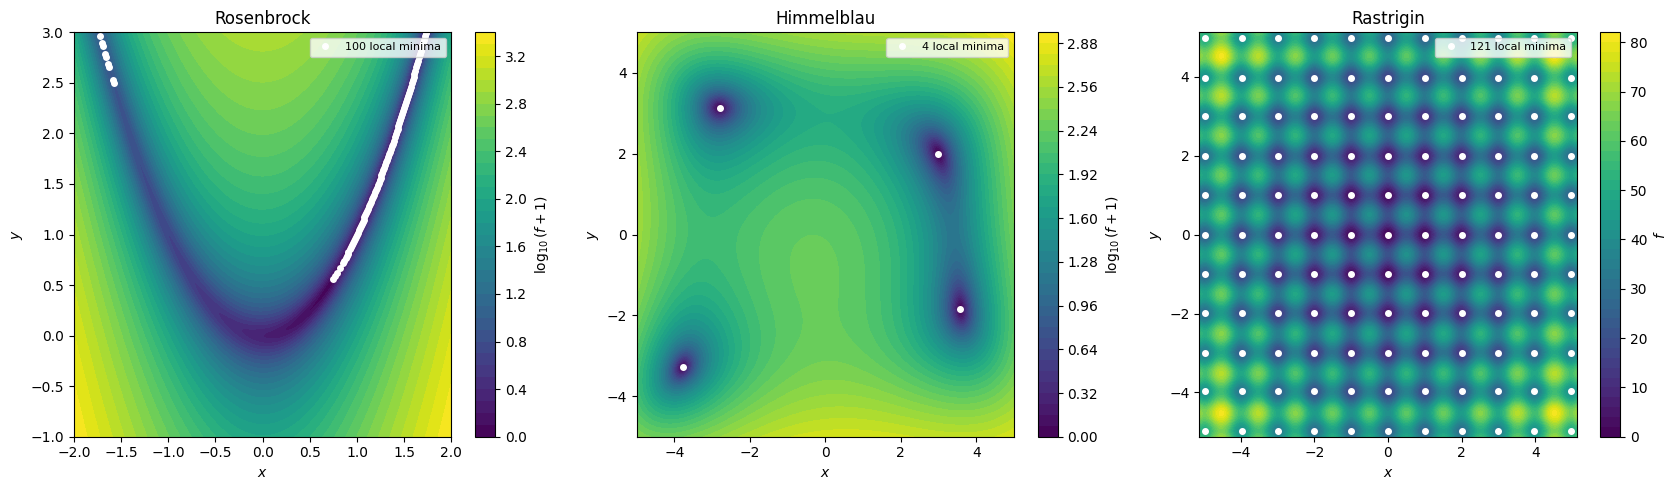

Rosenbrock: number of grid minima for 101, 401, 1601 points per axis: [39, 100, 205]
Himmelblau: number of grid minima for 101, 401, 1601 points per axis: [4, 4, 4]


Rastrigin : number of grid minima for 101, 401, 1601 points per axis: [121, 121, 121]


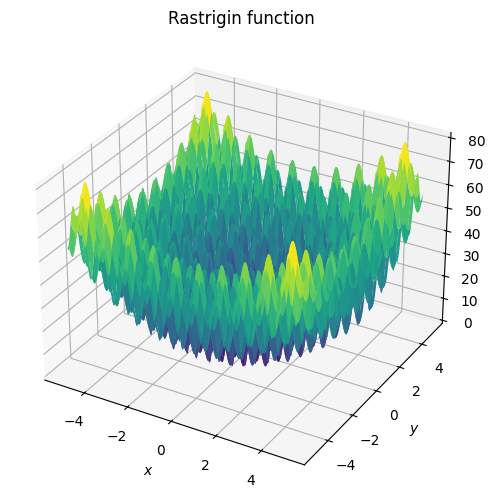

In [45]:
# 1) The three functions. Only element-wise operations are used, so they work on whole arrays.
def rosenbrock(X, Y):
    return (1 - X)**2 + 100 * (Y - X**2)**2

def himmelblau(X, Y):
    return (X**2 + Y - 11)**2 + (X + Y**2 - 7)**2

def rastrigin(X, Y):
    return 20 + X**2 + Y**2 - 10 * np.cos(2 * np.pi * X) - 10 * np.cos(2 * np.pi * Y)

def local_minima(Z):
    # 4) A point is a local minimum if it is smaller than all 8 neighbours.
    #    Z[1:-1, 1:-1] are the interior points; each shifted slice holds one neighbour of every interior point.
    c = Z[1:-1, 1:-1]
    neighbours = [Z[:-2, 1:-1], Z[2:, 1:-1], Z[1:-1, :-2], Z[1:-1, 2:],     # up, down, left, right
                  Z[:-2, :-2], Z[:-2, 2:], Z[2:, :-2], Z[2:, 2:]]          # four diagonals
    is_min = np.ones_like(c, dtype=bool)         # array of the same shape as c, filled with True
    for nb_vals in neighbours:
        # '&=' combines with logical AND in place: stays True only if c is smaller than every neighbour.
        # The strict '<' means that points on a flat plateau (equal neighbours) are not counted.
        is_min &= c < nb_vals
    rows, cols = np.nonzero(is_min)              # indices of the True entries
    return rows + 1, cols + 1                    # +1: shift back from interior to full-grid indices

# 2) Contour plots. Each entry: (name, function, x-range, y-range, plot log10(f+1)?)
landscapes = [("Rosenbrock", rosenbrock, (-2, 2), (-1, 3), True),
              ("Himmelblau", himmelblau, (-5, 5), (-5, 5), True),
              ("Rastrigin",  rastrigin,  (-5.12, 5.12), (-5.12, 5.12), False)]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, func, xr, yr, use_log) in zip(axes, landscapes):
    # *xr unpacks the tuple into (start, stop); 401 points per axis is an arbitrary resolution
    # (the resolution dependence is examined below). [-5.12, 5.12] is the conventional Rastrigin test domain.
    xg = np.linspace(*xr, 401)
    yg = np.linspace(*yr, 401)
    X, Y = np.meshgrid(xg, yg)
    Z = func(X, Y)
    shown = np.log10(Z + 1) if use_log else Z
    cf = ax.contourf(X, Y, shown, levels=40, cmap="viridis")
    fig.colorbar(cf, ax=ax, label=r"$\log_{10}(f+1)$" if use_log else "$f$")

    r, c = local_minima(Z)
    ax.plot(xg[c], yg[r], "o", color="white", ms=4, label=f"{len(r)} local minima")
    print(f"{name:10s}: {len(r):3d} local minima on the grid; lowest value {Z[r, c].min():.2e}")
    ax.set_title(name); ax.set_xlabel("$x$"); ax.set_ylabel("$y$"); ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); plt.show()

# Does the number of minima depend on the grid resolution?
for name, func, xr, yr, _ in landscapes:
    counts = []
    for n in [101, 401, 1601]:
        X, Y = np.meshgrid(np.linspace(*xr, n), np.linspace(*yr, n))
        counts.append(len(local_minima(func(X, Y))[0]))
    print(f"{name:10s}: number of grid minima for 101, 401, 1601 points per axis: {counts}")
# Himmelblau (4) and Rastrigin (121) give the same count for every grid: these minima are real.
# For Rosenbrock the count grows with the resolution: these minima are artefacts of the grid.
# The valley floor y = x^2 is curved and narrower than the grid spacing; grid points that happen to lie
# very close to the floor are lower than all their 8 neighbours, which lie on the steep walls.
# A result that changes when the discretisation is refined should never be trusted.

# 3) 3D surface of the Rastrigin function
xg = np.linspace(-5.12, 5.12, 200)
X, Y = np.meshgrid(xg, xg)
fig = plt.figure(figsize=(8, 6))
ax3d = fig.add_subplot(projection="3d")
ax3d.plot_surface(X, Y, rastrigin(X, Y), cmap="viridis", linewidth=0)
ax3d.set_xlabel("$x$"); ax3d.set_ylabel("$y$"); ax3d.set_zlabel("$f$")
ax3d.set_title("Rastrigin function")
plt.show()

# Why log10(f + 1): Rosenbrock and Himmelblau span several orders of magnitude (up to about 2.5e3 and 9e2 on the plotted domains);
# on a linear colour scale the region around the minima would be a single colour. The +1 avoids log10(0).
#
# 5) Rosenbrock has a single (true) minimum: a ball reaches it from anywhere, but slowly along the flat valley.
#    Himmelblau has four minima of equal depth: the ball ends in one of them, depending on where it starts,
#    and every one of them is a global minimum. Rastrigin has 121 local minima on the plotted domain: a ball started
#    at random almost always stops in a local minimum near its starting point. Loss functions of neural
#    networks are high-dimensional and non-convex, so training can also stop in local minima.

### Exercise 5 — Pendulum class and numerical integration

The pendulum obeys
$$\ddot\theta = -\frac{g}{L}\sin\theta . \tag{29}$$
A computer cannot follow $\theta(t)$ continuously; it computes the state at discrete times
$$t_n = n\,\Delta t . \tag{30}$$
The second-order equation is first written as **two first-order equations** for the angle $\theta$ and the angular velocity $\omega$:
$$\dot\theta = \omega,\qquad \dot\omega = -\frac{g}{L}\sin\theta . \tag{31}$$
For a small time step $\Delta t$ a derivative is approximately a difference quotient,
$$\dot\theta \approx \frac{\theta_{n+1} - \theta_n}{\Delta t}, \tag{32}$$
and the same for $\omega$. Solving for the new values gives an **update rule**. There are two natural versions.

In the *explicit Euler* method both updates use the old values:
$$\theta_{n+1} = \theta_n + \omega_n\,\Delta t,\qquad \omega_{n+1} = \omega_n - \frac{g}{L}\sin\theta_n\,\Delta t . \tag{33}$$

In the *semi-implicit Euler* method (also called symplectic Euler or Euler–Cromer) we first update $\omega$, then use the **new** $\omega$ to update $\theta$:
$$\omega_{n+1} = \omega_n - \frac{g}{L}\sin\theta_n\,\Delta t,\qquad \theta_{n+1} = \theta_n + \omega_{n+1}\,\Delta t . \tag{34}$$

The two rules differ only in the order of two lines of code, yet they behave very differently over long times. Explicit Euler systematically
**adds energy**, so that the trajectory in the phase plane $(\theta, \omega)$ spirals outwards. Semi-implicit Euler belongs to the class of *symplectic*
integrators, which respect the geometric structure of Hamiltonian dynamics (conservation of phase-space area): its energy error does not grow but
oscillates around zero. Both methods have an error per unit time proportional to $\Delta t$; more accurate methods (such as Runge–Kutta) exist,
but the difference between the two Euler variants already shows that the choice of integrator matters for physics.
The `Particle.step` method of Section 4.3 uses the semi-implicit rule as well.

Write a class `Pendulum` with
- attributes `length`, `g`, `theta`, `omega`, set in `__init__` (with default `g = 9.81`);
- a method `step(dt)` implementing the semi-implicit Euler rule, and a method `step_explicit(dt)` implementing the explicit Euler rule;
- a method `energy()` returning the energy per unit mass,
$$\frac{E}{m} = \tfrac12 L^2\omega^2 - g L\cos\theta ; \tag{35}$$
- a `__repr__` showing the current state.

Then carry out two tasks:
1. Create three pendulums released from rest at $10^\circ$, $90^\circ$ and $170^\circ$ (length 1 m), simulate 10 s with the time step $10^{-3}$ s using `step`, and plot $\theta(t)$
   for all three in one panel and the relative energy error
$$\frac{E(t) - E(0)}{g L} \tag{36}$$
   in a second panel. Explain why the period of the $170^\circ$ pendulum is much longer.
   The error is divided by the energy scale $gL$ and not by the initial energy, because for the pendulum released at $90^\circ$ equation (35) gives
$$E(0) = -gL\cos 90^\circ = 0 . \tag{37}$$
2. For the $90^\circ$ pendulum compare `step` and `step_explicit` with the larger step $10^{-2}$ s: plot both trajectories in the phase plane $(\theta, \omega)$
   and both energy errors versus time.

#### Solution

[Pendulum(l=1.0, theta=0.175, omega=0.000), Pendulum(l=1.0, theta=1.571, omega=0.000), Pendulum(l=1.0, theta=2.967, omega=0.000)]


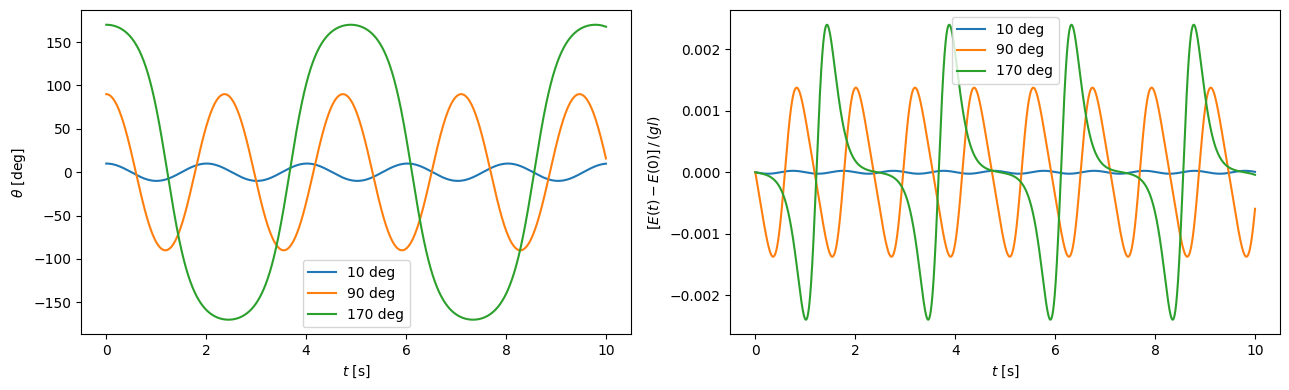

[Pendulum(l=1.0, theta=0.172, omega=0.084), Pendulum(l=1.0, theta=0.277, omega=-4.343), Pendulum(l=1.0, theta=2.927, omega=-0.390)]
explicit Euler      : energy error after 10 s = +0.702 g l,  largest |error| = 0.702 g l
semi-implicit Euler : energy error after 10 s = -0.006 g l,  largest |error| = 0.014 g l


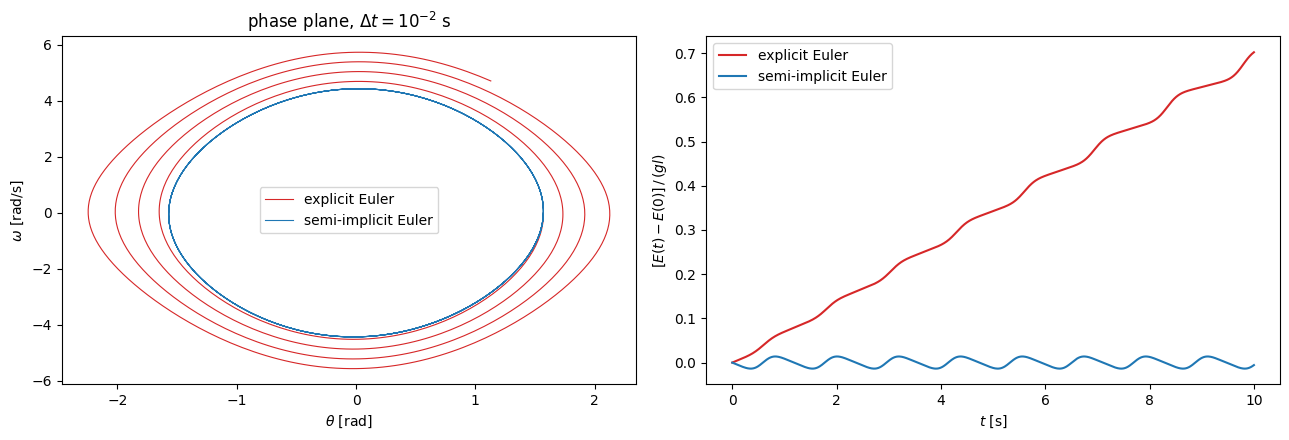

In [46]:
class Pendulum:
    """A simple pendulum of length `length` (point mass, massless rod)."""

    def __init__(self, length, theta, omega=0.0, g=9.81):
        self.length = length
        self.g = g
        self.theta = theta          # angle from the downward vertical [rad]
        self.omega = omega          # angular velocity d(theta)/dt [rad/s]

    def angular_acceleration(self):
        """Right-hand side of the equation of motion: d(omega)/dt = -(g/l) sin(theta)."""
        return -self.g / self.length * np.sin(self.theta)

    def step(self, dt):
        """Semi-implicit (symplectic) Euler step."""
        # 1) new angular velocity from the CURRENT angle:  omega_{n+1} = omega_n + alpha(theta_n) dt
        self.omega = self.omega + self.angular_acceleration() * dt
        # 2) new angle from the NEW angular velocity:     theta_{n+1} = theta_n + omega_{n+1} dt
        #    (self.omega already holds omega_{n+1}, because line 1 has been executed)
        self.theta = self.theta + self.omega * dt

    def step_explicit(self, dt):
        """Explicit Euler step: both updates use the values from the beginning of the step."""
        alpha = self.angular_acceleration()          # alpha(theta_n), computed BEFORE theta changes
        theta_old, omega_old = self.theta, self.omega
        self.theta = theta_old + omega_old * dt      # uses omega_n, not omega_{n+1}
        self.omega = omega_old + alpha * dt

    def energy(self):
        """Energy per unit mass: kinetic l^2 omega^2 / 2 plus potential -g l cos(theta)."""
        return 0.5 * self.length**2 * self.omega**2 - self.g * self.length * np.cos(self.theta)

    def __repr__(self):
        return f"Pendulum(l={self.length}, theta={self.theta:.3f}, omega={self.omega:.3f})"

# ---- Task 1: three amplitudes, semi-implicit Euler, dt = 1e-3 s
amplitudes = [10, 90, 170]
pendulums = [Pendulum(1.0, np.deg2rad(a)) for a in amplitudes]
print(pendulums)                                   # the list is printed using __repr__ of each object

dt, n_steps = 1e-3, 10_000
t = np.arange(n_steps + 1) * dt                    # np.arange(n) = 0, 1, ..., n-1 -> times 0, dt, ..., n_steps*dt
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for p, a in zip(pendulums, amplitudes):
    thetas, energies = [p.theta], [p.energy()]
    for _ in range(n_steps):                       # '_' is the usual name for a loop variable that is not used
        p.step(dt)
        thetas.append(p.theta); energies.append(p.energy())
    energies = np.array(energies)
    axes[0].plot(t, np.rad2deg(thetas), label=f"{a} deg")
    # divide by the energy scale g*l, NOT by energies[0]: at 90 deg the initial energy is 0
    # (numerically about 6e-16), and dividing by it would give meaningless values of order 1e13
    axes[1].plot(t, (energies - energies[0]) / (p.g * p.length), label=f"{a} deg")
axes[0].set_xlabel("$t$ [s]"); axes[0].set_ylabel(r"$\theta$ [deg]"); axes[0].legend()
axes[1].set_xlabel("$t$ [s]"); axes[1].set_ylabel(r"$[E(t) - E(0)]\,/\,(g l)$"); axes[1].legend()
fig.tight_layout(); plt.show()
print(pendulums)                                   # the objects now hold the final states
# Near 180 deg the pendulum starts close to the unstable upright position, where the restoring
# torque (g/l) sin(theta) is very small; it spends a long time there before falling, so the period grows
# (it diverges logarithmically as the amplitude approaches 180 deg).

# ---- Task 2: explicit vs semi-implicit Euler for the 90 deg pendulum, larger step dt = 1e-2 s
# The step is ten times larger than in Task 1 so that the drift of explicit Euler is large enough to see:
# after 10 s its energy error is about 0.07 g l with dt = 1e-3 and about 0.7 g l with dt = 1e-2.
dt2, n2 = 1e-2, 1000
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method, color in [("step_explicit", "C3"), ("step", "C0")]:
    p = Pendulum(1.0, np.deg2rad(90))
    E0 = p.energy()
    th, om, dE = [p.theta], [p.omega], [0.0]
    for _ in range(n2):
        getattr(p, method)(dt2)          # call p.step(dt2) or p.step_explicit(dt2) by the method's name
        th.append(p.theta); om.append(p.omega); dE.append((p.energy() - E0) / (p.g * p.length))
    label = "explicit Euler" if method == "step_explicit" else "semi-implicit Euler"
    axes[0].plot(th, om, color=color, lw=0.8, label=label)
    axes[1].plot(np.arange(n2 + 1) * dt2, dE, color=color, label=label)
    print(f"{label:20s}: energy error after 10 s = {dE[-1]:+.3f} g l,  largest |error| = {np.max(np.abs(dE)):.3f} g l")
axes[0].set_xlabel(r"$\theta$ [rad]"); axes[0].set_ylabel(r"$\omega$ [rad/s]"); axes[0].legend()
axes[0].set_title(r"phase plane, $\Delta t = 10^{-2}$ s")
axes[1].set_xlabel("$t$ [s]"); axes[1].set_ylabel(r"$[E(t) - E(0)]\,/\,(g l)$"); axes[1].legend()
fig.tight_layout(); plt.show()
# Explicit Euler: the curve in the phase plane spirals outwards and the energy grows steadily.
# Semi-implicit Euler: the curve closes on itself and the energy error oscillates around zero.

### Exercise 6 — Extending the `Polynomial` class
Extend `Polynomial` from Section 4.5 by inheritance: write `class Polynomial2(Polynomial)` that adds
- a method `derivative()` returning a new `Polynomial2` with coefficients $(c_1, 2c_2, 3c_3, \dots)$;
- `__mul__(self, other)` for the product of two polynomials (*hint:* `np.convolve(a, b)` multiplies coefficient lists).

Test: for
$$p(x) = 1 - 2x^2,\qquad q(x) = 3x \tag{38}$$
check the product rule
$$(pq)' = p'q + pq' \tag{39}$$
at several points. `p + q` (inherited `__add__`) returns a `Polynomial`, not a `Polynomial2`. Explain the reason and how this could be changed.

#### Solution

In [47]:
class Polynomial2(Polynomial):
    """Polynomial with derivative and multiplication."""

    def derivative(self):
        k = np.arange(1, len(self.c))                 # powers 1, 2, 3, ...
        return Polynomial2(k * self.c[1:])            # d/dx c_k x^k = k c_k x^(k-1)

    def __mul__(self, other):
        # the coefficient of x^k in the product is sum_i a_i b_(k-i): exactly the discrete convolution of the two lists
        return Polynomial2(np.convolve(self.c, other.c))

p, q = Polynomial2([1, 0, -2]), Polynomial2([0, 3])
lhs = (p * q).derivative()
# 'lambda x: expression' defines a short function without a name (equivalent to a def with one return line)
rhs_values = lambda x: p.derivative()(x) * q(x) + p(x) * q.derivative()(x)
xs = np.array([-1.0, 0.5, 2.0])
print("(pq)'      :", lhs(xs))
print("p'q + pq'  :", rhs_values(xs))
print(type(p + q))
# __add__ is defined in Polynomial and explicitly creates Polynomial(a + b).
# Writing  return type(self)(a + b)  in Polynomial.__add__ would create an object of the same class as self,
# so subclasses would automatically get objects of their own type.

(pq)'      : [-15.   -1.5 -69. ]
p'q + pq'  : [-15.   -1.5 -69. ]
<class '__main__.Polynomial'>
